In [6]:
# ============================================================
# Case Study : DLBDSMLUSL01 — Task 1: Mental Health in Tech
# Course     : Machine Learning — Unsupervised Learning & Feature Engineering
# Author     : Massaquoi L. Dehmie
# Principle  : Observation -> Investigation -> Finding -> Implication
# Golden Rule: The raw dataset is strictly read-only and never modified.
# ============================================================

In [18]:
# --- Jupyter / notebook magic ---
%load_ext autoreload
%autoreload 2

# --- Standard library ---
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

# --- Local project package ---
from src.paths import DATA_RAW

# --- Data manipulation ---
import pandas as pd
import numpy as np

# --- Statistics ---
from scipy.stats import chi2_contingency, kruskal

# --- Visualisation ---
import matplotlib.pyplot as plt
import seaborn as sns

# --- Machine learning: preprocessing & decomposition ---
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# --- Machine learning: clustering ---
from sklearn.cluster import KMeans, AgglomerativeClustering

# --- Machine learning: metrics ---
from sklearn.metrics import (
    silhouette_score,
    calinski_harabasz_score,
    davies_bouldin_score,
    adjusted_rand_score,
)

# --- Machine learning: manifold learning ---
from sklearn.manifold import TSNE

# --- Machine learning: text feature extraction ---
from sklearn.feature_extraction.text import TfidfVectorizer

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


# 2. Raw Dataset Loading & Inventory

In [19]:
#  Load raw data


RAW_PATH = DATA_RAW / "mental-health-in-tech-2016.csv"

df_raw = pd.read_csv(RAW_PATH)

print(f"Dataset loaded: {df_raw.shape[0]:,} rows × {df_raw.shape[1]} columns")
print(f"Source: {RAW_PATH}")

Dataset loaded: 1,433 rows × 63 columns
Source: /home/massaquoi/projects/iu-mental-health-tech-clustering-caseStudy/data/raw/mental-health-in-tech-2016.csv


In [9]:


print(f"Dataset Shape: {df_raw.shape[0]} rows, {df_raw.shape[1]} columns")
print(f"Exact Duplicate Rows: {df_raw.duplicated().sum()}")

# 2. Inspect Column Names (Check for long questions & duplicate headers)
print("\n--- Column Index & Names ---")
for idx, col in enumerate(df_raw.columns):
    print(f"[{idx:02d}] {col}")

# 3. Comprehensive Audit Table: Dtype, Missingness, Cardinality, & Sample Values
audit_rows = []
for idx, col in enumerate(df_raw.columns):
    n_missing = df_raw[col].isna().sum()
    pct_missing = (n_missing / len(df_raw)) * 100
    n_unique = df_raw[col].nunique(dropna=True)
    dtype = str(df_raw[col].dtype)

    # Grab top 3 most frequent values to spot messy text or pipe-delimited multi-selects
    top_vals = df_raw[col].value_counts(dropna=True).head(3).to_dict()

    audit_rows.append({
        "idx": idx,
        "column": col[:60] + "..." if len(col) > 60 else col,
        "dtype": dtype,
        "missing_cnt": n_missing,
        "missing_pct": round(pct_missing, 1),
        "n_unique": n_unique,
        "top_3_values": top_vals
    })

audit_df = pd.DataFrame(audit_rows)
print("\n--- Data Audit Summary (Sorted by Missing %) ---")
display(audit_df.sort_values(by="missing_pct", ascending=False))

# 4. Numerical Outliers Check (Age + any other numeric columns)
num_cols = df_raw.select_dtypes(include=[np.number]).columns.tolist()
print(f"\nNumeric columns detected: {num_cols}")
for col in num_cols:
    print(f"\nSummary stats for '{col}':")
    print(df_raw[col].describe(percentiles=[0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99]))
    
    # Flag suspicious values specifically for age-like columns
    if "age" in col.lower():
        suspect_ages = df_raw[(df_raw[col] < 16) | (df_raw[col] > 80)][col].value_counts()
        print(f"Suspect Age values (<16 or >80):\n{suspect_ages}")

# 5. Structural Missingness Probe (Self-Employed Skip Logic)
# Dynamically locate the self-employed column
self_emp_col = [c for c in df_raw.columns if "self-employed" in c.lower()][0]
print(f"\n--- Missingness Breakdown by '{self_emp_col}' ---")
print("Group counts:\n", df_raw[self_emp_col].value_counts(dropna=False))

# Compare % missing within Self-Employed (1) vs Employed (0) for every column
struct_missing = (
    df_raw.groupby(self_emp_col, dropna=False)
      .apply(lambda g: g.isna().mean() * 100)
      .T
      .round(1)
)
struct_missing["diff_pct"] = (struct_missing.iloc[:, 0] - struct_missing.iloc[:, 1]).abs()
print("\nTop 20 Columns where Missingness Depends on Self-Employment:")
display(struct_missing.sort_values("diff_pct", ascending=False).head(20))

Dataset Shape: 1433 rows, 63 columns
Exact Duplicate Rows: 0

--- Column Index & Names ---
[00] Are you self-employed?
[01] How many employees does your company or organization have?
[02] Is your employer primarily a tech company/organization?
[03] Is your primary role within your company related to tech/IT?
[04] Does your employer provide mental health benefits as part of healthcare coverage?
[05] Do you know the options for mental health care available under your employer-provided coverage?
[06] Has your employer ever formally discussed mental health (for example, as part of a wellness campaign or other official communication)?
[07] Does your employer offer resources to learn more about mental health concerns and options for seeking help?
[08] Is your anonymity protected if you choose to take advantage of mental health or substance abuse treatment resources provided by your employer?
[09] If a mental health issue prompted you to request a medical leave from work, asking for that leav

,idx,column,dtype,missing_cnt,missing_pct,n_unique,top_3_values
19,19,If you have revealed a mental health issue to ...,str,1289,90.0,3,"{'I'm not sure': 66, 'No': 42, 'Yes': 36}"
23,23,"If yes, what percentage of your work time (tim...",str,1229,85.8,4,"{'1-25%': 92, '26-50%': 72, '51-75%': 26}"
3,3,Is your primary role within your company relat...,float64,1170,81.6,2,"{1.0: 248, 0.0: 15}"
16,16,Do you have medical coverage (private insuranc...,float64,1146,80.0,2,"{1.0: 185, 0.0: 102}"
18,18,If you have been diagnosed or treated for a me...,str,1146,80.0,5,"{'Not applicable to me': 101, 'No, because it ..."
...,...,...,...,...,...,...,...
55,55,What is your age?,int64,0,0.0,53,"{30: 94, 31: 82, 29: 79}"
57,57,What country do you live in?,str,0,0.0,53,"{'United States of America': 840, 'United King..."
59,59,What country do you work in?,str,0,0.0,53,"{'United States of America': 851, 'United King..."
61,61,Which of the following best describes your wor...,str,0,0.0,264,"{'Back-end Developer': 263, 'Front-end Develop..."



Numeric columns detected: ['Are you self-employed?', 'Is your employer primarily a tech company/organization?', 'Is your primary role within your company related to tech/IT?', 'Do you have medical coverage (private insurance or state-provided) which includes treatment of \xa0mental health issues?', 'Do you have previous employers?', 'Have you ever sought treatment for a mental health issue from a mental health professional?', 'What is your age?']

Summary stats for 'Are you self-employed?':
count    1433.000000
mean        0.200279
std         0.400349
min         0.000000
1%          0.000000
5%          0.000000
25%         0.000000
50%         0.000000
75%         0.000000
95%         1.000000
99%         1.000000
max         1.000000
Name: Are you self-employed?, dtype: float64

Summary stats for 'Is your employer primarily a tech company/organization?':
count    1146.000000
mean        0.770506
std         0.420691
min         0.000000
1%          0.000000
5%          0.000000
25

Are you self-employed?,0,1,diff_pct
How many employees does your company or organization have?,0.0,100.0,100.0
Is your employer primarily a tech company/organization?,0.0,100.0,100.0
Does your employer provide mental health benefits as part of healthcare coverage?,0.0,100.0,100.0
"Has your employer ever formally discussed mental health (for example, as part of a wellness campaign or other official communication)?",0.0,100.0,100.0
Is your anonymity protected if you choose to take advantage of mental health or substance abuse treatment resources provided by your employer?,0.0,100.0,100.0
Does your employer offer resources to learn more about mental health concerns and options for seeking help?,0.0,100.0,100.0
Do you think that discussing a physical health issue with your employer would have negative consequences?,0.0,100.0,100.0
Would you feel comfortable discussing a mental health disorder with your coworkers?,0.0,100.0,100.0
"If a mental health issue prompted you to request a medical leave from work, asking for that leave would be:",0.0,100.0,100.0
Do you think that discussing a mental health disorder with your employer would have negative consequences?,0.0,100.0,100.0


# Phase 1: Data Audit & Structural Integrity Report (Step 1.1)

**Project:** Mental Health in Technology-Related Jobs (Unsupervised Learning Case Study)  
**Dataset:** OSMI Mental Health in Tech Survey (2016)  
**Objective:** Conduct an initial structural, data-type, cardinality, missingness, and outlier audit prior to data cleaning, feature selection, or clustering.

---

## 1. Dataset Overview & Structural Integrity

* **Dimensions:** `1,433` observations (rows) × `63` features (columns).
* **Exact Duplicate Rows:** `0` exact duplicate records detected.
* **Header & Schema Observations:**
  * Column headers consist of full-sentence survey questions (indices `[00]`–`[62]`), creating readability overhead.
  * **Duplicate Column Labels:** Two distinct open-ended questions share the identical header `"Why or why not?"` (indices `[37]` and `[39]`, disambiguated by `pandas` as `Why or why not?.1`).
  * **Hidden Whitespace Encoding:** Index `[16]` contains a non-breaking space character (`\xa0`) before `"mental health issues?"`, posing a risk of silent `KeyError` failures if referenced manually without string normalization.

---

## 2. Feature Taxonomy & Numeric Audit

Although `pandas` detected `7` numeric columns, inspection of their distributions confirms that **`6` are binary indicators (`0`/`1`)** rather than continuous quantities, leaving **`What is your age?` (`[55]`) as the sole continuous numeric feature**:

| Index | Feature (Abbreviated) | Non-Null Count | Mean / Proportion | Scale / Role |
| :--- | :--- | :---: | :---: | :--- |
| `[00]` | Self-employed? | 1,433 | 0.200 (20.0% Yes) | Binary (Survey Branching Key) |
| `[02]` | Employer primarily tech? | 1,146 | 0.771 (77.1% Yes) | Binary (Employed Branch) |
| `[03]` | Primary role tech/IT? | 263 | 0.943 (94.3% Yes) | Binary (Non-Tech Employer Sub-branch) |
| `[16]` | Has mental health medical coverage? | 287 | 0.645 (64.5% Yes) | Binary (Self-Employed Branch) |
| `[24]` | Has previous employers? | 1,433 | 0.882 (88.2% Yes) | Binary (Historical Branching Key) |
| `[52]` | Ever sought professional treatment? | 1,433 | 0.585 (58.5% Yes) | Binary (Clinical History) |
| `[55]` | **Age** | **1,433** | **Mean: 34.29 (SD: 11.29)** | **Continuous Numeric** |

### Continuous Outlier Analysis (`What is your age?`)
* **Central Tendency & Spread:** Median = `33`, IQR = `28–39`, 1st–99th percentile = `21.0–58.68` years.
* **Implausible Outliers Detected (`< 16` or `> 80`):** Four extreme values (`3`, `15`, `99`, and `323`, 1 record each) distort the sample range (`min = 3`, `max = 323`) and inflate the standard deviation (`11.29`).
* **Modeling Risk:** Because `Age` is the only continuous feature, uncleaned extreme values (especially `323`) will severely skew variance-based scaling (`StandardScaler` / `MinMaxScaler`) and distort Euclidean distances during clustering.

---

## 3. Missing Value Mechanisms: Structural vs. Random Missingness

Cross-tabulating feature missingness against `Are you self-employed?` (`[00]`) proves that the highest missingness rates in this dataset are **Missing Not At Random (MNAR) / Structural Missingness** caused by survey skip logic—not random data loss.

### A. Primary Branching: Employed vs. Self-Employed (`100%` Deterministic Split)
* **Employed Respondents (`0`):** `1,146` rows (`80.0%`)
* **Self-Employed Respondents (`1`):** `287` rows (`20.0%`)

This split produces an exact inverse missingness block across the survey:
1. **Current Employer Block (`[01]`–`[15]`):** `0.0%` missing for employed respondents (`n = 1,146`) and `100.0%` missing for self-employed respondents (`n = 287`).
2. **Self-Employed / Freelancer Block (`[16]`–`[22]`):** `100.0%` missing for employed respondents and `0.0%` missing for self-employed respondents (`n = 287`).

### B. Secondary & Nested Skip Logic
* **Non-Tech Employer Follow-up (`[03]`):** Missing for `1,170` rows (`81.6%`). The remaining `263` non-null entries correspond precisely to the `~22.9%` of employed respondents (`1,146 × (1 - 0.7705) ≈ 263`) whose primary employer is *not* a tech company (`[02] == 0`).
* **Employer Coverage Awareness (`[05]`):** Missing for `100.0%` of self-employed respondents and `11.6%` of employed respondents (conditional on employer benefit availability in `[04]`).
* **Deeply Nested Conditional Questions:**
  * `[19]` (Negative impact of disclosing to clients): `90.0%` missing (`n = 144` non-null; conditional on self-employment and disclosure).
  * `[23]` (% of work time affected by mental health): `85.8%` missing (`n = 204` non-null; conditional on `[22]`).
* **Previous Employer History (`[25]`–`[35]`):** Conditional on `[24]` (`88.2%` reported having previous employers).

---

## 4. High-Cardinality, Free-Text, & Domain Bias Observations

1. **Multi-Select Delimited Feature (`[61]` Work Position):** Contains `264` unique string values with `0` missing rows (e.g., `Back-end Developer`: 263, `Front-end Developer`: 125). Because respondents could select multiple roles concatenated into single strings, treating raw strings as atomic categories would cause severe dimensionality inflation during encoding.
2. **Open-Ended Text Fields (`[37]`, `[39]`):** Free-text justifications (`"Why or why not?"`) are unsuitable for standard tabular distance metrics without separate NLP feature extraction.
3. **Geographic Skew (`[57]`, `[59]`):** `53` unique countries, heavily concentrated in the United States (`~59%` of sample: 840 living / 851 working) and the United Kingdom (`~13%`: 180 living / 183 working).
4. **Remote Work (`[62]`):** Complete coverage (`0` missing) across 3 clean categories (`Sometimes`: 757, `Always`: 343, `Never`: 333).
5. **Sampling & Selection Bias Warning:** `58.5%` of respondents reported seeking professional mental health treatment (`[52]`). Because OSMI is a voluntary online survey distributed within tech/mental-health communities, prevalence rates likely reflect self-selection bias and should not be generalized as an unbiased global baseline.

---

## 5. Methodological Justification (Audit Decisions)

* **Why Structural Missingness Was Audited Before Dropping or Imputing Columns:**  
  Standard heuristic thresholds (e.g., dropping columns with `>50%` missing values) or blind global imputation (e.g., mode/KNN imputation) would be methodologically invalid here. Removing high-missingness columns indiscriminately would discard valid sub-population features (such as `[03]` or `[16]`), while imputing employer-policy questions onto self-employed respondents would fabricate corporate HR attributes for freelancers. Auditing missingness conditionally against branching keys preserves survey logic for downstream scoping (e.g., deciding whether internal HR modeling should restrict the population to `self_employed == 0`).
* **Why Numeric Outliers Were Flagged Early:**  
  Identifying impossible `Age` entries (`3`, `15`, `99`, `323`) prior to exploratory visualization and scaling prevents extreme values from masking distribution structure and guarantees that future distance calculations reflect genuine demographic variation rather than data-entry noise.
* **Next Audit Requirement:** Complete full inspection of the remaining mid-table categorical/free-text columns truncated in the summary view (specifically `[56]` Gender, `[58]`/`[60]` US States, and `[48]`/`[49]`/`[51]` diagnosed/suspected conditions) before finalizing cleaning rules.

=== COMPLETE 63-COLUMN AUDIT ===
[00] (int64 | miss=0 (0.0%) | uniq=2) Are you self-employed?
     -> {0: 1146, 1: 287}
[01] (str | miss=287 (20.0%) | uniq=6) How many employees does your company or organization have?
     -> {'26-100': 292, 'More than 1000': 256, '100-500': 248, '6-25': 210, '500-1000': 80, '1-5': 60}
[02] (float64 | miss=287 (20.0%) | uniq=2) Is your employer primarily a tech company/organization?
     -> {1.0: 883, 0.0: 263}
[03] (float64 | miss=1170 (81.6%) | uniq=2) Is your primary role within your company related to tech/IT?
     -> {1.0: 248, 0.0: 15}
[04] (str | miss=287 (20.0%) | uniq=4) Does your employer provide mental health benefits as part of healthcare coverage?
     -> {'Yes': 531, "I don't know": 319, 'No': 213, 'Not eligible for coverage / N/A': 83}
[05] (str | miss=420 (29.3%) | uniq=3) Do you know the options for mental health care available under your employer-provided coverage?
     -> {'No': 354, 'I am not sure': 352, 'Yes': 307}
[06] (str | miss

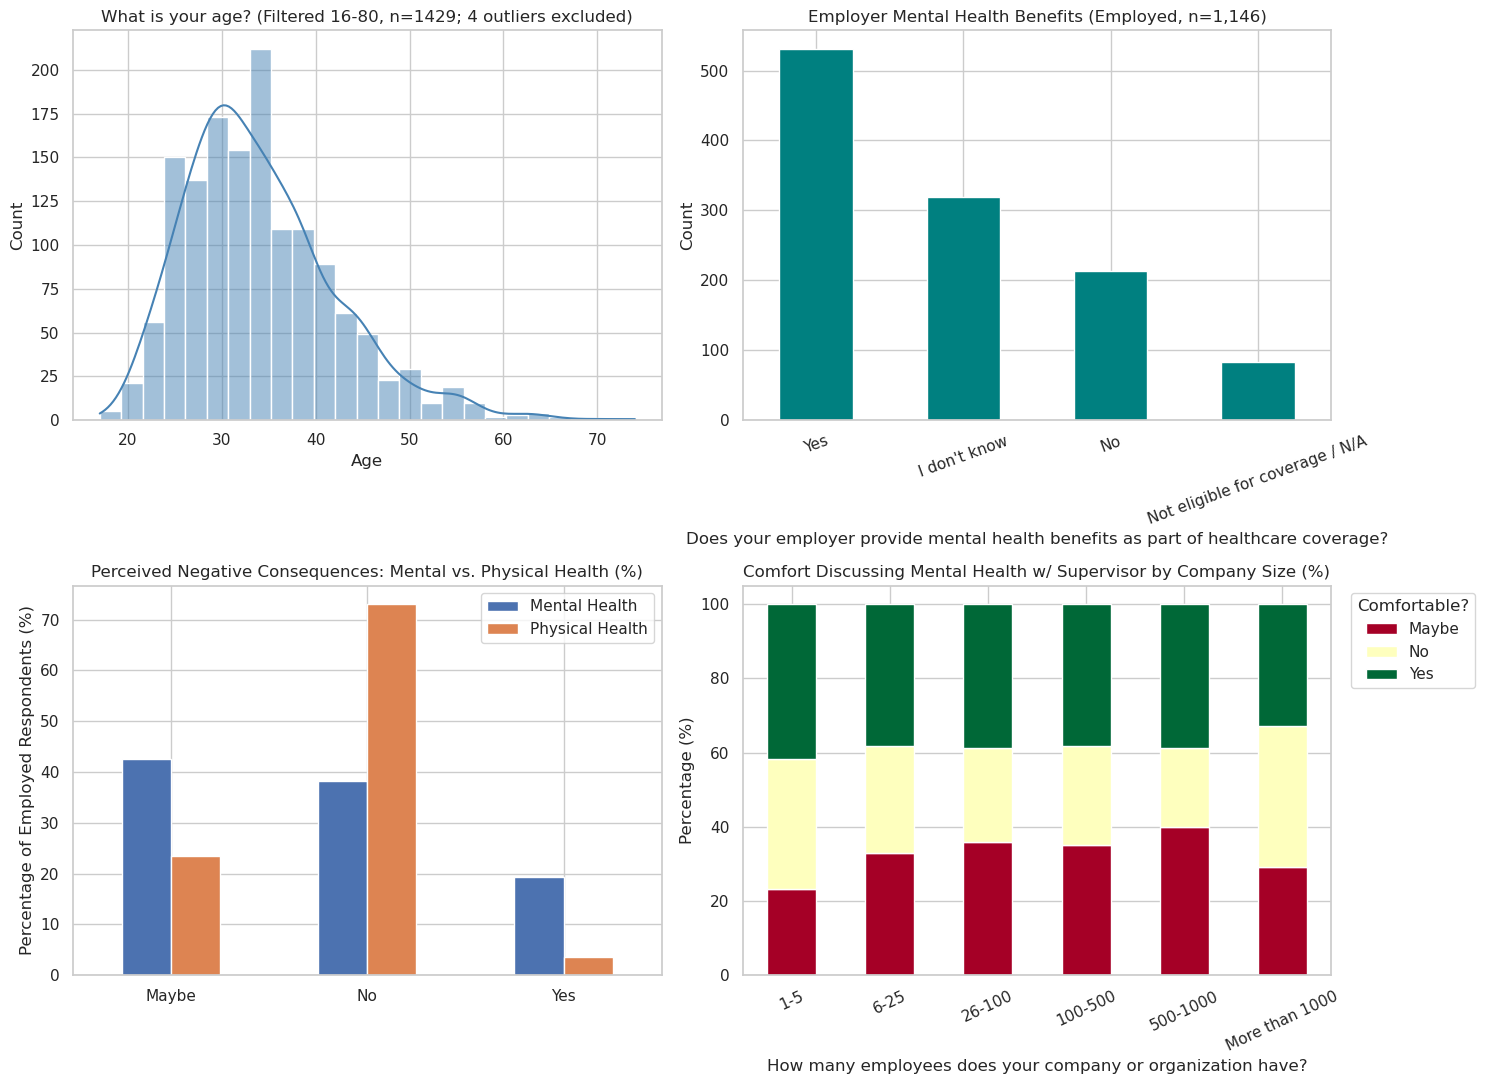

In [10]:
# Ensure full visibility (no truncation of rows or column text)
pd.set_option('display.max_rows', None)
pd.set_option('display.max_colwidth', None)

# 1. Full 63-Column Audit (No Truncation)
full_audit = []
for idx, col in enumerate(df_raw.columns):
    n_miss = df_raw[col].isna().sum()
    pct_miss = round((n_miss / len(df_raw)) * 100, 1)
    n_uniq = df_raw[col].nunique(dropna=True)
    # Get all unique value counts if low cardinality (<= 6), else top 3
    vc = df_raw[col].value_counts(dropna=True)
    summary_vals = vc.to_dict() if n_uniq <= 6 else vc.head(3).to_dict()
    
    full_audit.append({
        "idx": idx,
        "feature_name": col,
        "dtype": str(df_raw[col].dtype),
        "missing_cnt": n_miss,
        "missing_pct": pct_miss,
        "n_unique": n_uniq,
        "value_summary": summary_vals
    })

full_audit_df = pd.DataFrame(full_audit)
print("=== COMPLETE 63-COLUMN AUDIT ===")
for _, r in full_audit_df.iterrows():
    print(f"[{r['idx']:02d}] ({r['dtype']} | miss={r['missing_cnt']} ({r['missing_pct']}%) | uniq={r['n_unique']}) {r['feature_name']}")
    print(f"     -> {r['value_summary']}")

# 2. Deep-Dive into Messy Free-Text & Pipe-Delimited Multi-Select Columns
print("\n=== MESSY TEXT & MULTI-SELECT INSPECTION ===")

gender_col = "What is your gender?"
print(f"\n'{gender_col}' - Unique values ({df_raw[gender_col].nunique(dropna=True)}):")
print(df_raw[gender_col].value_counts(dropna=False).head(30))

pos_col = "Which of the following best describes your work position?"
# Split pipe-delimited positions to see true atomic job roles
atomic_roles = df_raw[pos_col].dropna().str.split("|").explode().value_counts()
print(f"\n'{pos_col}' - Atomic Role Counts after splitting '|' ({len(atomic_roles)} distinct roles):")
print(atomic_roles)

cond_cols = [
    "If yes, what condition(s) have you been diagnosed with?",
    "If maybe, what condition(s) do you believe you have?",
    "If so, what condition(s) were you diagnosed with?"
]
for c in cond_cols:
    atomic_conds = df_raw[c].dropna().str.split("|").explode().value_counts()
    print(f"\n'{c}' - Atomic Condition Counts ({df_raw[c].notna().sum()} respondents):")
    print(atomic_conds.head(15))

# 3. Verify Secondary Skip-Logic Branches (Previous Employers & Diagnosis)
print("\n=== SECONDARY SKIP-LOGIC VERIFICATION ===")
prev_emp_col = "Do you have previous employers?"
print(f"\nMissingness of '[25] Have your previous employers provided mental health benefits?' by '{prev_emp_col}':")
print(df_raw.groupby(prev_emp_col)["Have your previous employers provided mental health benefits?"].apply(lambda s: s.isna().sum()))

curr_mh_col = "Do you currently have a mental health disorder?"
print(f"\nCross-tab '{curr_mh_col}' vs non-null count of '[48] If yes...' and '[49] If maybe...':")
print(df_raw.groupby(curr_mh_col)[[
    "If yes, what condition(s) have you been diagnosed with?",
    "If maybe, what condition(s) do you believe you have?"
]].count())

med_diag_col = "Have you been diagnosed with a mental health condition by a medical professional?"
print(f"\nCross-tab '{med_diag_col}' vs non-null count of '[51] If so, what condition(s) were you diagnosed with?':")
print(df_raw.groupby(med_diag_col)["If so, what condition(s) were you diagnosed with?"].count())

# 4. Baseline Visual EDA (Focus on Employed Population for HR Relevance)
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(2, 2, figsize=(15, 11))

# Plot A: Age Distribution (Valid Working-Age Range 16-80 highlighted)
valid_ages = df_raw.loc[(df_raw["What is your age?"] >= 16) & (df_raw["What is your age?"] <= 80), "What is your age?"]
sns.histplot(valid_ages, bins=25, kde=True, ax=axes[0, 0], color="steelblue")
axes[0, 0].set_title(f"What is your age? (Filtered 16-80, n={len(valid_ages)}; 4 outliers excluded)")
axes[0, 0].set_xlabel("Age")

# Filter to employed respondents (n = 1,146) for HR-actionable plots B, C, D
emp_df = df_raw[df_raw["Are you self-employed?"] == 0]

# Plot B: Mental Health Benefits vs. Awareness Gap
emp_df["Does your employer provide mental health benefits as part of healthcare coverage?"].value_counts().plot(
    kind="bar", ax=axes[0, 1], color="teal", rot=20
)
axes[0, 1].set_title("Employer Mental Health Benefits (Employed, n=1,146)")
axes[0, 1].set_ylabel("Count")

# Plot C: Mental vs. Physical Health Stigma Comparison
stigma_comp = pd.DataFrame({
    "Mental Health": emp_df["Do you think that discussing a mental health disorder with your employer would have negative consequences?"].value_counts(normalize=True) * 100,
    "Physical Health": emp_df["Do you think that discussing a physical health issue with your employer would have negative consequences?"].value_counts(normalize=True) * 100
})
stigma_comp.plot(kind="bar", ax=axes[1, 0], rot=0)
axes[1, 0].set_title("Perceived Negative Consequences: Mental vs. Physical Health (%)")
axes[1, 0].set_ylabel("Percentage of Employed Respondents (%)")

# Plot D: Company Size vs. Comfort Discussing with Direct Supervisor
size_order = ['1-5', '6-25', '26-100', '100-500', '500-1000', 'More than 1000']
ct_sup = pd.crosstab(
    emp_df["How many employees does your company or organization have?"],
    emp_df["Would you feel comfortable discussing a mental health disorder with your direct supervisor(s)?"],
    normalize="index"
).reindex(size_order) * 100
ct_sup.plot(kind="bar", stacked=True, ax=axes[1, 1], rot=25, colormap="RdYlGn")
axes[1, 1].set_title("Comfort Discussing Mental Health w/ Supervisor by Company Size (%)")
axes[1, 1].set_ylabel("Percentage (%)")
axes[1, 1].legend(title="Comfortable?", bbox_to_anchor=(1.02, 1), loc="upper left")

plt.tight_layout()
plt.show()

# Phase 1: Complete Feature Audit, Hidden Semantics & Baseline Visual EDA (Step 1.2)

**Project:** Mental Health in Technology-Related Jobs (Unsupervised Learning Case Study)  
**Dataset:** OSMI Mental Health in Tech Survey (2016) — `1,433` rows × `63` columns  
**Objective:** Inspect all 63 features without truncation, quantify multi-select and free-text cardinality, verify secondary skip-logic branches, and establish baseline HR insights via visual EDA.

---

## 1. Complete Skip-Logic & Structural Missingness Verification

Extending Step 1.1, all remaining missingness patterns across the 63 features were confirmed to be **deterministic survey branching (MNAR)** rather than random data corruption:

* **Current Employer Branch (`[01]`–`[15]`):** `287` missing (`20.0%`), matching the exact count of `Are you self-employed? == 1`.
  * *Nested Sub-branch:* `Is your primary role within your company related to tech/IT?` (`[03]`) has `1,170` missing (`81.6%`), leaving `263` responses—exclusively those where `Is your employer primarily a tech company/organization? == 0` (`248` tech-role, `15` non-tech-role).
  * *Nested Sub-branch:* `Do you know the options for mental health care available under your employer-provided coverage?` (`[05]`) has `420` missing (`29.3%`), reflecting respondents who are self-employed (`287`) plus employed respondents without or ineligible for coverage.
* **Self-Employed Branch (`[16]`–`[23]`):** `1,146` missing (`80.0%`), matching `Are you self-employed? == 0`, with deeper conditional follow-ups on `[19]` (`1,289` missing / `90.0%`) and `[23]` (`1,229` missing / `85.8%`).
* **Previous Employer Branch (`[25]`–`[35]`):** Exactly `169` missing (`11.8%`) across all 11 columns, verified `100%` against `Do you have previous employers? == 0` (`169` respondents).
* **Workplace Observation Follow-up (`[44]`):** `Have your observations of how another individual who discussed a mental health disorder made you less likely to reveal a mental health issue yourself in your current workplace?` has `776` missing (`54.2%`), conditional on responses to `[43]` (`Have you observed or experienced an unsupportive or badly handled response to a mental health issue in your current or previous workplace?`, which itself has `89` missing / `6.2%`).
* **Mental Health Condition Follow-ups (`[48]`, `[49]`, `[51]`):**
  * `If yes, what condition(s) have you been diagnosed with?` (`[48]`): `568` non-null (`865` missing / `60.4%`), populated exclusively when `Do you currently have a mental health disorder? == "Yes"` (`575` rows; `7` skipped specifying).
  * `If maybe, what condition(s) do you believe you have?` (`[49]`): `322` non-null (`1,111` missing / `77.5%`), populated exclusively when `Do you currently have a mental health disorder? == "Maybe"` (`327` rows; `5` skipped specifying).
  * `If so, what condition(s) were you diagnosed with?` (`[51]`): `711` non-null (`722` missing / `50.4%`), populated exclusively when `Have you been diagnosed with a mental health condition by a medical professional? == "Yes"` (`716` rows; `5` skipped specifying).
* **US Geographic Sub-branches (`[58]`, `[60]`):**
  * `What US state or territory do you live in?` (`[58]`): `593` missing (`41.4%`), matching `1,433 - 840` non-US residents (`What country do you live in?`).
  * `What US state or territory do you work in?` (`[60]`): `582` missing (`40.6%`), matching `1,433 - 851` non-US workers (`What country do you work in?`).

---

## 2. Messy Free-Text & Pipe-Delimited Multi-Select Audit

### A. Free-Text Chaos in `What is your gender?` (`[56]`)
* **Missing:** `3` rows (`0.2%`).
* **Cardinality:** `70` unique raw string values caused by inconsistent casing, abbreviations, trailing whitespace, and open-text entries (e.g., `'Male'`: 610, `'male'`: 249, `'M'`: 86, `'m'`: 79, `'Male '`: 11; `'Female'`: 153, `'female'`: 95, `'F'`: 38, `'f'`: 23, `'Female '`: 9).
* **Inclusive Representation:** Non-binary, trans, and gender-diverse identities appear in smaller counts (`'non-binary'`: 4, `'Agender'`: 2, `'Nonbinary'`: 2, `'Bigender'`: 1, `'Transitioned, M2F'`: 1, `'Genderfluid (born female)'`: 1, `'Other/Transfeminine'`: 1). Text standardization must consolidate casing/synonyms **without** erasing non-binary/trans categories into noise.

### B. Pipe-Delimited Multi-Selects (`|`)
1. **`Which of the following best describes your work position?` (`[61]`):**
   * Raw unique strings: `264` (combinatorial multi-selects).
   * Exploding on `|` reduces this cleanly to **`12` atomic tech/organizational roles**: `Back-end Developer` (`737`), `Front-end Developer` (`502`), `DevOps/SysAdmin` (`282`), `Supervisor/Team Lead` (`277`), `Other` (`187`), `Support` (`168`), `One-person shop` (`161`), `Designer` (`135`), `Executive Leadership` (`101`), `Dev Evangelist/Advocate` (`99`), `Sales` (`31`), and `HR` (`12`).
2. **Condition Multi-Selects (`[48]`, `[49]`, `[51]`):**
   * Raw combinations ranged from `99` to `128` unique strings (`[48]`: 128, `[49]`: 99, `[51]`: 116).
   * Exploding on `|` reveals a consistent clinical core led by `Mood Disorder (Depression, Bipolar Disorder, etc)` (`412` current / `526` medically diagnosed), `Anxiety Disorder (Generalized, Social, Phobia, etc)` (`345` current / `373` medically diagnosed), `Attention Deficit Hyperactivity Disorder` (`121` / `134`), `Post-traumatic Stress Disorder` (`69` / `70`), and `Obsessive-Compulsive Disorder` (`45` / `40`), plus occasional free-text write-ins (e.g., `'Burnout'`, `'Depression'`, `'Autism'`, `'We\'re all hurt, right?!'`).

### C. Open-Ended Qualitative Fields (`[37]`, `[39]`)
* `Why or why not?` (`[37]`: `338` missing, `1,085` unique) and `Why or why not?.1` (`[39]`: `307` missing, `1,080` unique) are free-text explanations for interview disclosure choices (`[36]`, `[38]`). They are unsuitable for direct distance-based tabular clustering but valuable for post-hoc qualitative cluster narrative profiling.

---

## 3. Baseline Exploratory Visual & HR Analytics Findings

Analyzing the **valid working-age distribution (`16–80`, `n = 1,429`)** and the **employed sub-population (`Are you self-employed? == 0`, `n = 1,146`)** surfaces five immediate HR points of leverage:

1. **Demographic Core (`What is your age?`):** Right-skewed distribution peaking sharply around ages `28–35` (median `33`), confirming a predominantly early-to-mid-career tech workforce once the 4 extreme outliers (`3`, `15`, `99`, `323`) are excluded.
2. **The Benefit & Communication Awareness Gap (`[04]`–`[08]`):**
   * On `Does your employer provide mental health benefits as part of healthcare coverage?` (`[04]`): `531` (`46.3%`) answered `'Yes'`, `213` (`18.6%`) `'No'`, `83` (`7.2%`) `'Not eligible for coverage / N/A'`, and **`319` (`27.8%`) answered `'I don\'t know'`**.
   * On `Do you know the options for mental health care available under your employer-provided coverage?` (`[05]`): Only `307` of `1,146` employed respondents (`26.8%`) answered `'Yes'`, while `354` answered `'No'` and `352` answered `'I am not sure'`.
   * On `Has your employer ever formally discussed mental health...` (`[06]`): `813` (`70.9%`) answered `'No'`.
   * On `Is your anonymity protected if you choose to take advantage of mental health or substance abuse treatment resources provided by your employer?` (`[08]`): **`742` (`64.7%`) answered `'I don\'t know'`**.
3. **Mental vs. Physical Health Stigma Asymmetry (`[10]` vs. `[11]`):**
   * On `Do you think that discussing a mental health disorder with your employer would have negative consequences?` (`[10]`): `42.5%` answered `'Maybe'` (`487`) and `19.3%` answered `'Yes'` (`221`)—meaning **`61.8%` perceive potential or definite negative consequences**.
   * By contrast, on `Do you think that discussing a physical health issue with your employer would have negative consequences?` (`[11]`): `73.0%` answered `'No'` (`837`) and only `3.6%` answered `'Yes'` (`41`)—more than **5× lower definite stigma** than mental health.
4. **Supervisor Comfort Across Company Sizes (`[01]` × `[13]`):**
   * Across all company sizes (`1-5` up to `More than 1000`), roughly `32%–41%` feel comfortable (`'Yes'`) discussing a mental health disorder with their direct supervisor, while `~59%–68%` remain hesitant or uncomfortable (`'Maybe'` or `'No'`). Large enterprises (`More than 1000`) exhibit the lowest `'Yes'` comfort (`~32%`) and highest `'No'` discomfort (`~38%`), indicating that formal corporate scale does not automatically produce psychological safety.
5. **Productivity ROI of Effective Treatment (`[53]` vs. `[54]`):**
   * On `If you have a mental health issue, do you feel that it interferes with your work when being treated effectively?` (`[53]`): Only `65` respondents report `'Often'` interference (`322` `'Rarely'`, `120` `'Never'`).
   * On `If you have a mental health issue, do you feel that it interferes with your work when NOT being treated effectively?` (`[54]`): `'Often'` interference surges over **8×** to `538` respondents (and `'Never'` drops to `12`), providing direct empirical justification for pre-emptive HR access and stigma-reduction programs.

---

## 4. Methodological Justification (EDA Completion)

* **Why `"I don't know"` and `"Not eligible for coverage / N/A"` Must Not Be Treated as Missing (`NaN`):**  
  In organizational HR data, epistemic uncertainty (`"I don't know"`) is a substantive behavioral signal rather than missing data. An employee who does not know whether anonymity is protected (`64.7%` in `[08]`) or whether benefits exist (`27.8%` in `[04]`) behaves similarly to an uncovered employee in terms of under-utilizing support. Preserving `"I don't know"` as an explicit category (or encoding policy certainty ordinally) captures HR's largest communication gap.
* **Why Exploding Pipe-Delimited Multi-Selects Was Essential:**  
  Treating raw concatenated strings in `Which of the following best describes your work position?` (`264` unique values) or condition fields (`99`–`128` unique values) as atomic categories would create extreme sparsity and treat two overlapping roles (e.g., `Back-end Developer|DevOps/SysAdmin` vs. `Back-end Developer`) as 100% unrelated. Exploding into atomic binary indicators preserves true role/condition overlap.

### Key Architectural Question: Should our clustering algorithm use:

- **Approach A** ("HR-Actionable Workplace & Stigma Clustering"): Cluster employees using Blocks 1 + 2 (current workplace policies/awareness + stigma/psychological safety attitudes, plus optional light context like What is your age?, Do you work remotely?, How many employees does your company or organization have?), and hold out Block 3 (Clinical Status & Interference) and Block 4 (Demographics/Roles) for Post-Hoc Cluster Profiling?
Why this is brilliant for HR: It avoids trivial clusters ("Healthy vs. Diagnosed") and instead uncovers actionable organizational personas (e.g., "Covered but Anonymity-Skeptical", "High-Stigma / Unaware", "Supported & Psychologically Safe"). Then, when we overlay Clinical Status & Untreated Work Interference ([47], [52], [54]) onto each cluster, HR can see which workplace environment correlates with untreated struggle and high work interference!

- **Approach B** ("Holistic Employee Persona Clustering"): Include Blocks 1 + 2 + 3 (workplace + stigma + clinical history/treatment) directly inside the clustering algorithm so clusters also reflect mental health need directly.

In [ ]:
# 1. Filter to Target Cohort: Employed AND (Tech Employer OR Tech Role)
cohort_mask = (
    (df_raw["Are you self-employed?"] == 0) &
    (
        (df_raw["Is your employer primarily a tech company/organization?"] == 1.0) |
        (df_raw["Is your primary role within your company related to tech/IT?"] == 1.0)
    )
)
tech_df = df_raw[cohort_mask].copy().reset_index(drop=True)
print(f"Target Cohort Shape: {tech_df.shape[0]} rows, {tech_df.shape[1]} columns")

# 2. Define Feature Blocks for Approach A 
# Block 1 + 2: Clustering Inputs (Workplace Environment, Awareness, Stigma & Psychological Safety)
cluster_cols = [
    "How many employees does your company or organization have?",
    "Is your employer primarily a tech company/organization?",
    "Does your employer provide mental health benefits as part of healthcare coverage?",
    "Do you know the options for mental health care available under your employer-provided coverage?",
    "Has your employer ever formally discussed mental health (for example, as part of a wellness campaign or other official communication)?",
    "Does your employer offer resources to learn more about mental health concerns and options for seeking help?",
    "Is your anonymity protected if you choose to take advantage of mental health or substance abuse treatment resources provided by your employer?",
    "If a mental health issue prompted you to request a medical leave from work, asking for that leave would be:",
    "Do you think that discussing a mental health disorder with your employer would have negative consequences?",
    "Do you think that discussing a physical health issue with your employer would have negative consequences?",
    "Would you feel comfortable discussing a mental health disorder with your coworkers?",
    "Would you feel comfortable discussing a mental health disorder with your direct supervisor(s)?",
    "Do you feel that your employer takes mental health as seriously as physical health?",
    "Have you heard of or observed negative consequences for co-workers who have been open about mental health issues in your workplace?",
    "Would you be willing to bring up a physical health issue with a potential employer in an interview?",
    "Would you bring up a mental health issue with a potential employer in an interview?",
    "Do you feel that being identified as a person with a mental health issue would hurt your career?",
    "Do you think that team members/co-workers would view you more negatively if they knew you suffered from a mental health issue?",
    "How willing would you be to share with friends and family that you have a mental illness?",
    "Have you observed or experienced an unsupportive or badly handled response to a mental health issue in your current or previous workplace?",
    "Have your observations of how another individual who discussed a mental health disorder made you less likely to reveal a mental health issue yourself in your current workplace?",
    "Do you work remotely?"
]

# Block 3 + 4: Post-Hoc Profiling Columns (Clinical Outcomes, Work Interference, Demographics, Roles)
profile_cols = [
    "Do you have a family history of mental illness?",
    "Have you had a mental health disorder in the past?",
    "Do you currently have a mental health disorder?",
    "Have you been diagnosed with a mental health condition by a medical professional?",
    "Have you ever sought treatment for a mental health issue from a mental health professional?",
    "If you have a mental health issue, do you feel that it interferes with your work when being treated effectively?",
    "If you have a mental health issue, do you feel that it interferes with your work when NOT being treated effectively?",
    "What is your age?",
    "What is your gender?",
    "What country do you work in?",
    "Which of the following best describes your work position?"
]

# 3. Missingness Audit Within Target Cohort (n = 1,131)
print("\n=== MISSINGNESS IN CLUSTERING INPUTS (n = 1,131) ===")
miss_clust = tech_df[cluster_cols].isna().sum()
print(miss_clust[miss_clust > 0])

print("\n=== MISSINGNESS IN PROFILING COLUMNS (n = 1,131) ===")
miss_prof = tech_df[profile_cols].isna().sum()
print(miss_prof[miss_prof > 0])

# 4. Forensic Check on Conditional Skip-Logic Inside Target Cohort
print("\n--- Check [04] vs [05] (Benefits vs Options Awareness) ---")
print(pd.crosstab(
    tech_df["Does your employer provide mental health benefits as part of healthcare coverage?"],
    tech_df["Do you know the options for mental health care available under your employer-provided coverage?"].fillna("MISSING_NaN"),
    dropna=False
))

print("\n--- Check [43] vs [44] (Observed Unsupportive Response vs Less Likely to Reveal) ---")
print(pd.crosstab(
    tech_df["Have you observed or experienced an unsupportive or badly handled response to a mental health issue in your current or previous workplace?"].fillna("MISSING_NaN"),
    tech_df["Have your observations of how another individual who discussed a mental health disorder made you less likely to reveal a mental health issue yourself in your current workplace?"].fillna("MISSING_NaN"),
    dropna=False
))

# 5. Forensic Inspection of Age Outliers Inside Target Cohort
age_outliers = tech_df[(tech_df["What is your age?"] < 18) | (tech_df["What is your age?"] > 80)]
print(f"\n=== AGE OUTLIERS IN TARGET COHORT ({len(age_outliers)} rows) ===")
if len(age_outliers) > 0:
    display(age_outliers[[
        "What is your age?", "What is your gender?", "What country do you work in?",
        "How many employees does your company or organization have?",
        "Which of the following best describes your work position?",
        "Why or why not?", "Why or why not?.1"
    ]])

# 6. Full Unique List of Gender Entries in Target Cohort (to build a lossless mapping)
print(f"\n=== ALL UNIQUE GENDER STRINGS IN TARGET COHORT ({tech_df['What is your gender?'].nunique(dropna=True)}) ===")
print(tech_df["What is your gender?"].value_counts(dropna=False).to_dict())

Target Cohort Shape: 1131 rows, 63 columns

=== MISSINGNESS IN CLUSTERING INPUTS (n = 1,131) ===
Do you know the options for mental health care available under your employer-provided coverage?                                                                                     133
Have you observed or experienced an unsupportive or badly handled response to a mental health issue in your current or previous workplace?                                           51
Have your observations of how another individual who discussed a mental health disorder made you less likely to reveal a mental health issue yourself in your current workplace?    629
dtype: int64

=== MISSINGNESS IN PROFILING COLUMNS (n = 1,131) ===
What is your gender?    3
dtype: int64

--- Check [04] vs [05] (Benefits vs Options Awareness) ---
Do you know the options for mental health care available under your employer-provided coverage?  I am not sure  \
Does your employer provide mental health benefits as part of healthcare

,What is your age?,What is your gender?,What country do you work in?,How many employees does your company or organization have?,Which of the following best describes your work position?,Why or why not?,Why or why not?.1
73,17,male,Brazil,6-25,Front-end Developer,Starting a job hiding something like this can be a really bad way to get the trust of the employees.,Same response as the physical one.
312,99,Other,United States of America,6-25,Supervisor/Team Lead,"It would be something they would need to know, so better to know if it's the type of place that does or doesn't understand that.","It depends on the employer. See, it's difficult to answer survey questions that require generalizing all previous employers. I've had productive conversations with some; even so, at one place a mental health issue conversation resulted in immediate retribution."
462,323,Male,United States of America,100-500,Back-end Developer,It may affect time I need to take off or my ability to do certain tasks.,It hasn't come up for me.
536,3,Male,Canada,More than 1000,Back-end Developer,Legislation in my jurisdiction mandates certain protections for employees who need concessions due to health.,"Despite the legal protections, mental health in my area still suffers a significant amount stigma."



=== ALL UNIQUE GENDER STRINGS IN TARGET COHORT (60) ===
{'Male': 501, 'male': 194, 'Female': 118, 'female': 76, 'M': 69, 'm': 55, 'F': 23, 'f': 20, 'Female ': 6, 'Male ': 5, 'non-binary': 4, 'woman': 4, nan: 3, 'man': 2, 'Male (cis)': 2, 'female ': 2, 'Agender': 2, 'male ': 2, 'I identify as female.': 1, 'Bigender': 1, 'Female assigned at birth ': 1, 'fm': 1, 'Cis female ': 1, 'Transitioned, M2F': 1, 'Genderfluid (born female)': 1, 'Other/Transfeminine': 1, 'Female or Multi-Gender Femme': 1, 'female/woman': 1, 'Cis male': 1, 'Male.': 1, 'Androgynous': 1, 'male 9:1 female, roughly': 1, 'Other': 1, 'nb masculine': 1, 'Cisgender Female': 1, 'Man': 1, 'Sex is male': 1, 'none of your business': 1, 'genderqueer': 1, 'cis male': 1, 'Human': 1, 'Genderfluid': 1, 'Enby': 1, 'genderqueer woman': 1, 'Woman': 1, 'Queer': 1, 'Dude': 1, 'mail': 1, 'Male/genderqueer': 1, 'fem': 1, 'Nonbinary': 1, 'Female (props for making this a freeform field, though)': 1, 'Cis Male': 1, 'Male (trans, FtM)': 1, 'Ci

# Data Quality Report — Target Cohort (1,131 rows, 63 columns)

## 1. Size
The cohort has **1,131 people** and **63 columns**. All counts below use 1,131 as the total.

---

## 2. Missing values in the clustering inputs

| Feature | Missing | % |
|---|---|---|
| "Do you know the options for mental health care available under your employer-provided coverage?" | 133 | ~12% |
| "Have you observed or experienced an unsupportive or badly handled response to a mental health issue in your current or previous workplace?" | 51 | ~4.5% |
| "Have your observations of how another individual who discussed a mental health disorder made you less likely to reveal a mental health issue yourself in your current workplace?" | 629 | ~56% |

The third feature is more than half missing. Of the 629 missing, 488 (78%) answered "No" to "Have you observed or experienced an unsupportive or badly handled response to a mental health issue in your current or previous workplace?" — so the missingness is tied to the skip logic, not random loss.

---

## 3. Missing values in the profiling column

- **"What is your gender?"** — only **3 missing** (<0.3%).

---

## 4. Check: Benefits vs. Options Awareness

This compares **"Does your employer provide mental health benefits as part of healthcare coverage?"** with **"Do you know the options for mental health care available under your employer-provided coverage?"**

| Benefits answer | Not sure about options | Missing options | No (doesn't know options) | Yes (knows options) |
|---|---|---|---|---|
| I don't know | 156 | 6 | 149 | 5 |
| No | 34 | 72 | 84 | 20 |
| Not eligible / N/A | 15 | 55 | 8 | 3 |
| Yes | 144 | 0 | 108 | 272 |

Observations:
- The largest coherent cell is **272** people who say benefits = **Yes** and know the options = **Yes**.
- **156** people who **don't know** benefits are also **not sure** about options.
- **108** people say benefits exist but they **don't know the options**; another **144** are **not sure** about options despite saying benefits exist.
- Of the **133** people missing the options question, **127 (95%)** said benefits = **No** or **Not eligible**. Only **6** said "I don't know" and **0** said "Yes."
- **55 of 78** "Not eligible" respondents have missing options.

---

## 5. Check: Observed Unsupportive Response vs. Less Likely to Reveal

This compares **"Have you observed or experienced an unsupportive or badly handled response to a mental health issue in your current or previous workplace?"** with **"Have your observations of how another individual who discussed a mental health disorder made you less likely to reveal a mental health issue yourself in your current workplace?"**

Observations:
- Of the **629** people missing the "less likely to reveal" question, **488 (78%)** answered "No" to the unsupportive-response question, and **51** were also missing that question.
- **56** people missing "less likely to reveal" answered "Maybe/Not sure" to the unsupportive-response question, and **34** answered "Yes" (22 experienced + 12 observed).
- Among people who answered "less likely to reveal" = **Yes**: **49** had experienced an unsupportive response and **92** had only observed one.
- Among people who answered "Maybe": **62** said "Maybe/Not sure" to the unsupportive-response question, **21** experienced, **44** observed.
- Among people who answered "No": **115** said "Maybe/Not sure," **36** experienced, **44** observed.
- No contradictory cells appear in the cross-tab.

---

## 6. Age outliers

- **4 rows** are flagged as age outliers (about 0.35% of the cohort). The actual values are not shown in the file.

---

## 7. Gender strings — 60 unique values

The **"What is your gender?"** column is free text and contains 60 distinct strings.

| Group | Approx. count | Examples of raw strings |
|---|---|---|
| **Male / man** | ~839 | `Male`, `male`, `M`, `m`, `Male `, `man`, `Man`, `Cis male`, `cis male`, `Cis Male`, `cis man`, `cisdude`, `Dude`, `mail` (typo), `Sex is male`, `Male (trans, FtM)`, `male 9:1 female, roughly`, `Male/genderqueer` |
| **Female / woman** | ~263 | `Female`, `female`, `F`, `f`, `Female `, `female `, `woman`, `Woman`, `Cis female`, `Cis-woman`, `Cisgender Female`, `I identify as female.`, `Female assigned at birth`, `female-bodied; no feelings about gender`, `Female or Multi-Gender Femme`, `female/woman`, `fem`, `fm`, `Transitioned, M2F`, `Transgender woman`, `Female (props for making this a freeform field, though)` |
| **Non-binary / other** | ~25 | `non-binary`, `Nonbinary`, `Enby`, `nb masculine`, `Agender`, `Bigender`, `Genderfluid`, `Genderfluid (born female)`, `Genderflux demi-girl`, `genderqueer`, `Genderqueer`, `genderqueer woman`, `Queer`, `Androgynous`, `Other`, `Other/Transfeminine`, `Human`, `none of your business` |
| **Missing** | 3 | `nan` |

Additional observations:
- The same gender appears in multiple spellings (e.g., `Male`, `male`, `Male `, `M`, `m`).
- `mail` appears once and is a spelling of `male`.
- `M`/`m` together account for 124 people; `F`/`f` together account for 43 people.
- Trans and cis labels appear in several forms: `Male (trans, FtM)`, `Transitioned, M2F`, `Transgender woman`, `Cis male`, `Cis-woman`, `Cisgender Female`, `Cis female`, `cis male`, `Cis Male`, `cis man`, `cisdude`.
- Single-response joke or protest answers appear: `Human`, `Dude`, `none of your business` — one person each.
- Mixed or ambiguous answers appear: `Male/genderqueer`, `male 9:1 female, roughly`, `Female or Multi-Gender Femme`, `genderqueer woman` — one person each.
- 3 respondents have `nan` for gender.

---

## 8. Summary of observations

| Item | Observation |
|---|---|
| "Less likely to reveal" question | 629 missing (56%); 488 of those answered "No" to the unsupportive-response question |
| Options-awareness question | 133 missing (12%); 127 of those said benefits = "No" or "Not eligible" |
| Unsupportive-response question | 51 missing (4.5%) |
| Benefits vs. options cross-tab | 108 say benefits exist but don't know options; 144 are not sure; 272 are coherent Yes/Yes |
| Observed response vs. less likely to reveal | "Yes, less likely to reveal" = 49 experienced + 92 observed |
| Age outliers | 4 rows |
| Gender | 60 unique strings; 3 missing; case/whitespace noise dominates; `mail` typo present; 124 `M`/`m` and 43 `F`/`f`; several trans/cis and mixed labels |

In [12]:



# Work on a clean copy of the n=1,131 Tech-Employed cohort
clean_df = tech_df.copy()

# ==========================================
# 1. CLEAN PROFILING FEATURES (Blocks 3 & 4)
# ==========================================

# 1a. Age: Impute only impossible outliers (<16 or >80 -> 3, 99, 323) with cohort median; keep age 17
age_col = "What is your age?"
valid_age_mask = (clean_df[age_col] >= 16) & (clean_df[age_col] <= 80)
median_age = clean_df.loc[valid_age_mask, age_col].median()
clean_df["Age_Clean"] = clean_df[age_col].where(valid_age_mask, median_age)
print(f"Imputed {(~valid_age_mask).sum()} impossible age values with cohort median ({median_age}).")
print(f"Cleaned Age Range: {clean_df['Age_Clean'].min()} to {clean_df['Age_Clean'].max()}")

# 1b. Gender: Lossless mapping across all 60 unique raw strings + NaNs
def clean_gender(val):
    if pd.isna(val):
        return "Other / Undisclosed"
    s = str(val).strip().lower()
    
    male_set = {
        "male", "m", "man", "male (cis)", "cis male", "male.",
        "sex is male", "dude", "mail", "male (trans, ftm)", "cisdude", "cis man"
    }
    female_set = {
        "female", "f", "woman", "i identify as female.", "female assigned at birth",
        "cis female", "transitioned, m2f", "female/woman", "cisgender female",
        "fem", "female (props for making this a freeform field, though)",
        "cis-woman", "transgender woman"
    }
    nb_set = {
        "non-binary", "agender", "bigender", "genderfluid (born female)",
        "other/transfeminine", "female or multi-gender femme", "androgynous",
        "male 9:1 female, roughly", "nb masculine", "genderqueer", "genderfluid",
        "enby", "genderqueer woman", "queer", "male/genderqueer", "nonbinary",
        "genderflux demi-girl", "female-bodied; no feelings about gender"
    }
    
    if s in male_set:
        return "Male"
    elif s in female_set:
        return "Female"
    elif s in nb_set:
        return "Non-Binary / Gender-Diverse"
    else:
        return "Other / Undisclosed"

clean_df["Gender_Clean"] = clean_df["What is your gender?"].apply(clean_gender)
print("\nCleaned Gender Distribution (n = 1,131):")
print(clean_df["Gender_Clean"].value_counts())

# 1c. Explode Work Position into binary role indicators (for post-hoc HR profiling)
pos_dummies = (
    clean_df["Which of the following best describes your work position?"]
    .str.get_dummies(sep="|")
    .add_prefix("Role_")
)
clean_df = pd.concat([clean_df, pos_dummies], axis=1)
print(f"\nCreated {pos_dummies.shape[1]} binary Role profiling columns.")

# ==========================================
# 2. RESOLVE CONDITIONAL MISSINGNESS IN CLUSTERING INPUTS
# ==========================================

col_04 = "Does your employer provide mental health benefits as part of healthcare coverage?"
col_05 = "Do you know the options for mental health care available under your employer-provided coverage?"
col_43 = "Have you observed or experienced an unsupportive or badly handled response to a mental health issue in your current or previous workplace?"
col_44 = "Have your observations of how another individual who discussed a mental health disorder made you less likely to reveal a mental health issue yourself in your current workplace?"

# [05]: Structural skip when employer provides no / N/A / unknown coverage
clean_df[col_05] = clean_df[col_05].fillna("Not applicable / No coverage")

# [43]: 51 respondents did not answer
clean_df[col_43] = clean_df[col_43].fillna("No response")

# [44]: Distinguish structural skip ([43] == 'No') from other skips
def fill_col_44(row):
    if pd.notna(row[col_44]):
        return row[col_44]
    elif row[col_43] == "No":
        return "Not applicable (No unsupportive obs)"
    else:
        return "Skipped / Unsure"

clean_df[col_44] = clean_df.apply(fill_col_44, axis=1)

# Verify zero missing values remain across all 22 clustering inputs
remaining_na = clean_df[cluster_cols].isna().sum().sum()
print(f"\nRemaining NaNs in clustering features: {remaining_na}")

# ==========================================
# 3. BUILD HYBRID BASELINE MATRIX (Ordinal + One-Hot)
# ==========================================

# 3a. Purely Ordered / Binary Features (Mapped to [0, 1] scale for balanced baseline weighting)
ordinal_maps = {
    "How many employees does your company or organization have?": {
        "1-5": 0.0, "6-25": 0.2, "26-100": 0.4,
        "100-500": 0.6, "500-1000": 0.8, "More than 1000": 1.0
    },
    "Is your employer primarily a tech company/organization?": {0.0: 0.0, 1.0: 1.0},
    "Do you think that discussing a mental health disorder with your employer would have negative consequences?": {
        "No": 0.0, "Maybe": 0.5, "Yes": 1.0
    },
    "Do you think that discussing a physical health issue with your employer would have negative consequences?": {
        "No": 0.0, "Maybe": 0.5, "Yes": 1.0
    },
    "Would you feel comfortable discussing a mental health disorder with your coworkers?": {
        "No": 0.0, "Maybe": 0.5, "Yes": 1.0
    },
    "Would you feel comfortable discussing a mental health disorder with your direct supervisor(s)?": {
        "No": 0.0, "Maybe": 0.5, "Yes": 1.0
    },
    "Have you heard of or observed negative consequences for co-workers who have been open about mental health issues in your workplace?": {
        "No": 0.0, "Yes": 1.0
    },
    "Would you be willing to bring up a physical health issue with a potential employer in an interview?": {
        "No": 0.0, "Maybe": 0.5, "Yes": 1.0
    },
    "Would you bring up a mental health issue with a potential employer in an interview?": {
        "No": 0.0, "Maybe": 0.5, "Yes": 1.0
    },
    "Do you work remotely?": {
        "Never": 0.0, "Sometimes": 0.5, "Always": 1.0
    }
}

X_ord = pd.DataFrame(index=clean_df.index)
for col, mapping in ordinal_maps.items():
    X_ord[col] = clean_df[col].map(mapping)
    assert X_ord[col].isna().sum() == 0, f"Unmapped value found in {col}!"

# 3b. Nominal / Epistemic Features (Contain "I don't know", "N/A", or non-monotonic categories -> One-Hot Encode)
nominal_cols = [c for c in cluster_cols if c not in ordinal_maps]
print(f"\nOrdinal/Binary features ({len(ordinal_maps)}), Nominal/Epistemic OHE features ({len(nominal_cols)}):")
for c in nominal_cols:
    print(f" - {c}")

X_ohe = pd.get_dummies(clean_df[nominal_cols], prefix_sep=" == ", dtype=float)

# Combine into Baseline Feature Matrix (unscaled & standardized versions)
X_base = pd.concat([X_ord, X_ohe], axis=1)
scaler = StandardScaler()
X_base_scaled = pd.DataFrame(
    scaler.fit_transform(X_base),
    columns=X_base.columns,
    index=X_base.index
)

print(f"\nFinal Baseline Feature Matrix Shape: {X_base_scaled.shape}")
print(f"Total Missing Values in X_base_scaled: {X_base_scaled.isna().sum().sum()}")

Imputed 3 impossible age values with cohort median (32.0).
Cleaned Age Range: 17 to 70

Cleaned Gender Distribution (n = 1,131):
Gender_Clean
Male                           841
Female                         260
Non-Binary / Gender-Diverse     23
Other / Undisclosed              7
Name: count, dtype: int64

Created 12 binary Role profiling columns.

Remaining NaNs in clustering features: 0

Ordinal/Binary features (10), Nominal/Epistemic OHE features (12):
 - Does your employer provide mental health benefits as part of healthcare coverage?
 - Do you know the options for mental health care available under your employer-provided coverage?
 - Has your employer ever formally discussed mental health (for example, as part of a wellness campaign or other official communication)?
 - Does your employer offer resources to learn more about mental health concerns and options for seeking help?
 - Is your anonymity protected if you choose to take advantage of mental health or substance abuse treatme

# Phase 2: Cohort Scoping, Cleaning & Hybrid Feature Engineering

**Project:** Mental Health in Technology-Related Jobs (Unsupervised Learning Case Study)  
**Target Sample:** `1,131` employed tech-sector / tech-role respondents  
**Feature Matrix Dimensions:** `1,131` rows × `62` standardized numeric features (`0` missing values)

---

## 1. Population Scoping & Approach A Architecture

1. **Strict Cohort Filtering (`n = 1,433` → `1,131`):**  
   To align strictly with an internal corporate HR intervention for technology-related roles, the sample was restricted to respondents satisfying:
   * `Are you self-employed? == 0` (excluding `287` freelancers/self-employed individuals), **AND**
   * `Is your employer primarily a tech company/organization? == 1.0` **OR** `Is your primary role within your company related to tech/IT? == 1.0` (excluding `15` non-tech employees in non-tech firms).  
   This eliminated `100%` of the self-employed structural missingness across employer policy columns (`[01]`–`[15]`) and rendered the self-employed block (`[16]`–`[23]`) inapplicable.

2. **Separation of Clustering Inputs vs. Post-Hoc Profiling Features (Approach A):**  
   To prevent circular clustering driven purely by clinical diagnosis status ("has disorder" vs. "no disorder"), **22 workplace environment, policy awareness, and stigma/psychological safety features** were selected as clustering inputs (`[01]`, `[02]`, `[04]`–`[15]`, `[36]`, `[38]`, `[40]`–`[44]`, `[62]`).  
   Clinical outcomes (`[45]`–`[54]`, e.g., `Do you currently have a mental health disorder?`, `Have you ever sought treatment for a mental health issue from a mental health professional?`, `If you have a mental health issue, do you feel that it interferes with your work when NOT being treated effectively?`) and demographic/role attributes (`What is your age?`, `What is your gender?`, `What country do you work in?`, `Which of the following best describes your work position?`) were held out strictly for **post-hoc cluster profiling**.

---

## 2. Outlier Forensics, Text Standardization & Missingness Resolution

1. **Forensic Resolution of `What is your age?` Outliers:**  
   Inspecting all rows with `What is your age? < 18` or `> 80` inside `n = 1,131` (`4` rows: ages `17`, `99`, `323`, and `3`) revealed that every respondent provided earnest, coherent qualitative responses in `Why or why not?` and `Why or why not?.1`. Consequently:
   * `Age = 17` (valid junior front-end developer) was **retained**.
   * The `3` biologically implausible entries (`3`, `99`, `323`) were imputed with the valid cohort median (**`32.0` years**), yielding a clean profiling range of **`17` to `70`**.

2. **Lossless Standardization of `What is your gender?` (`60` unique raw values + `3` missing → `4` clean categories):**  
   Casing inconsistencies, trailing whitespace, abbreviations, and open-text gender descriptions were consolidated into an inclusive 4-category profiling variable (`Gender_Clean`):
   * `Male`: `841` (`74.4%`)
   * `Female`: `260` (`23.0%`)
   * `Non-Binary / Gender-Diverse`: `23` (`2.0%`)
   * `Other / Undisclosed`: `7` (`0.6%`)

3. **Role Explosion for Profiling:**  
   `Which of the following best describes your work position?` was exploded on the `|` delimiter into **`12` binary `Role_*` indicator columns** for post-hoc organizational profiling.

4. **Deterministic Resolution of Conditional Missingness (`3` affected clustering columns):**  
   Cross-tabulation verified all remaining missing values in the `22` clustering inputs were conditional skips:
   * `Do you know the options for mental health care available under your employer-provided coverage?` (`133` missing): `127` answered `"No"` or `"Not eligible for coverage / N/A"` and `6` answered `"I don't know"` on `Does your employer provide mental health benefits as part of healthcare coverage?` (`0` answered `"Yes"`). Filled with `"Not applicable / No coverage"`.
   * `Have you observed or experienced an unsupportive or badly handled response to a mental health issue in your current or previous workplace?` (`51` missing): Filled with explicit `"No response"`.
   * `Have your observations of how another individual who discussed a mental health disorder made you less likely to reveal a mental health issue yourself in your current workplace?` (`629` missing): `488` had answered `"No"` to `[43]` and were mapped to `"Not applicable (No unsupportive obs)"`; the remaining `141` conditional skips were mapped to `"Skipped / Unsure"`.

---

## 3. Hybrid Baseline Encoding Strategy (`1,131 × 62`)

Rather than blindly applying One-Hot Encoding across all features (inflating sparsity) or blindly label-encoding nominal uncertainty categories, a **Hybrid Encoding Strategy** was implemented and standardized via `StandardScaler`:

* **`10` Monotonic Ordinal / Binary Features (Mapped to `[0, 1]`):**  
  Preserved directional magnitude for `How many employees does your company or organization have?`, `Is your employer primarily a tech company/organization?`, `Do you think that discussing a mental health disorder with your employer would have negative consequences?`, `Do you think that discussing a physical health issue with your employer would have negative consequences?`, `Would you feel comfortable discussing a mental health disorder with your coworkers?`, `Would you feel comfortable discussing a mental health disorder with your direct supervisor(s)?`, `Have you heard of or observed negative consequences for co-workers who have been open about mental health issues in your workplace?`, `Would you be willing to bring up a physical health issue with a potential employer in an interview?`, `Would you bring up a mental health issue with a potential employer in an interview?`, and `Do you work remotely?`.
* **`12` Nominal / Epistemic Features (One-Hot Encoded → `52` binary indicators):**  
  Features containing non-linear epistemic states (`"I don't know"`, `"Not eligible for coverage / N/A"`, `"Not applicable"`) or multi-state perceptions (e.g., `Does your employer provide mental health benefits as part of healthcare coverage?`, `Is your anonymity protected if you choose to take advantage of mental health or substance abuse treatment resources provided by your employer?`, `If a mental health issue prompted you to request a medical leave from work, asking for that leave would be:`, `Do you feel that your employer takes mental health as seriously as physical health?`, `Do you feel that being identified as a person with a mental health issue would hurt your career?`, etc.) were One-Hot Encoded to avoid imposing false linear orderings.

PC1 + PC2 Explained Variance: 16.31%
Components needed for 70% variance: 23 / 62
Components needed for 80% variance: 29 / 62

=== TOP POSITIVE & NEGATIVE LOADINGS ON PC1 ===
Do you think that discussing a mental health disorder with your employer would have negative consequences?                                                   0.300364
Do you think that team members/co-workers would view you more negatively if they knew you suffered from a mental health issue? == Yes, I think they would    0.229204
Do you feel that being identified as a person with a mental health issue would hurt your career? == Yes, I think it would                                    0.216861
Do you think that discussing a physical health issue with your employer would have negative consequences?                                                    0.197037
Do you feel that your employer takes mental health as seriously as physical health? == No                                                                    0.175

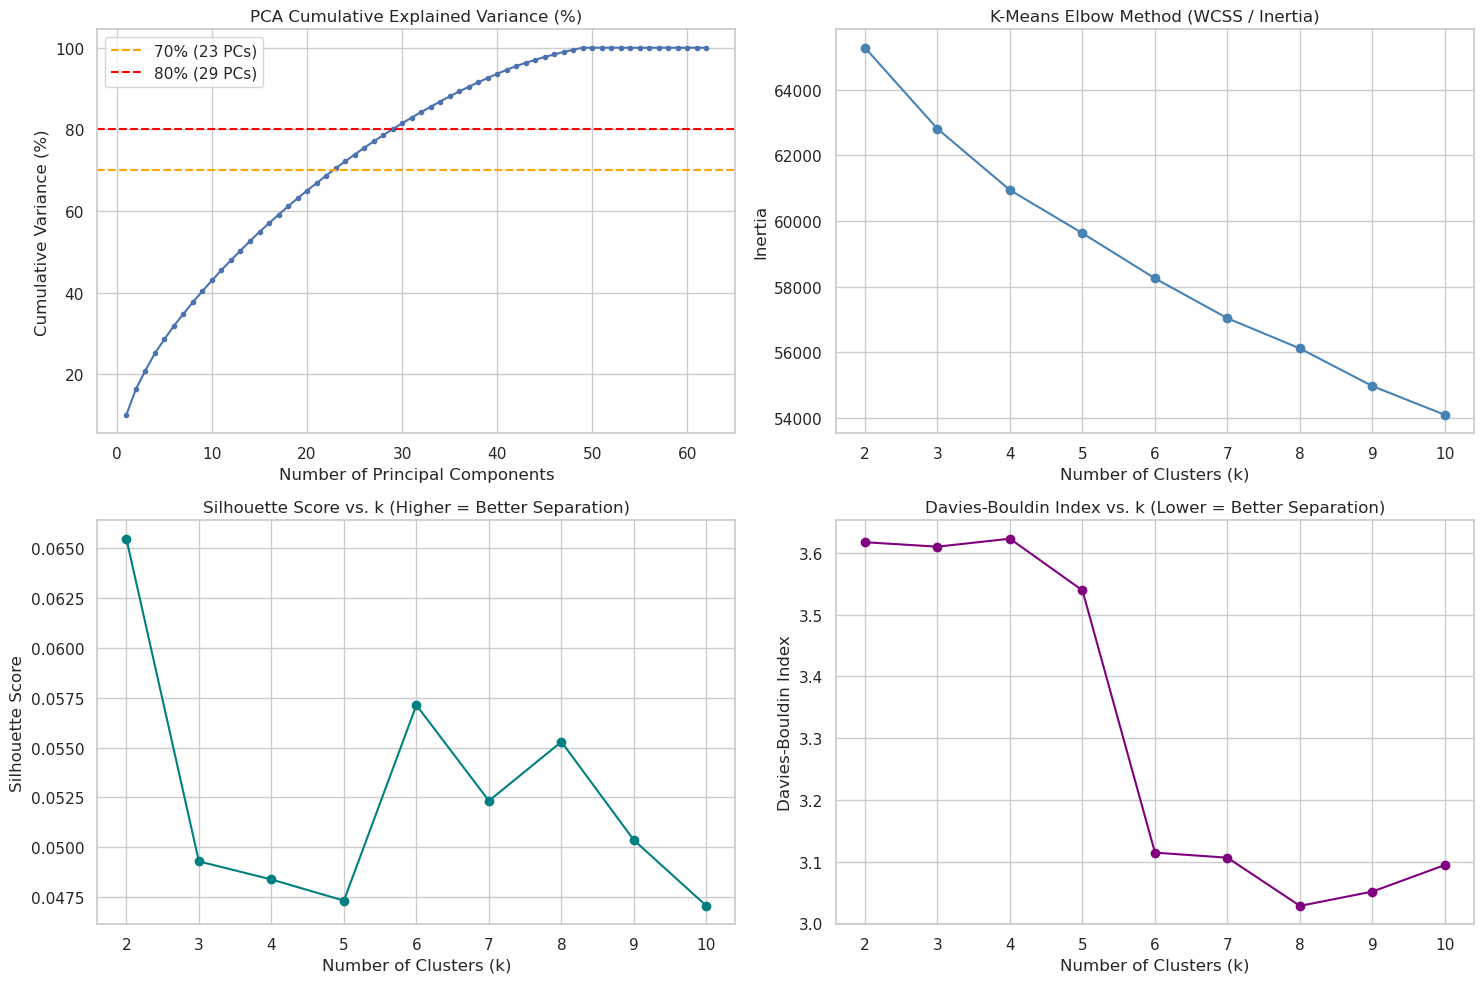

In [13]:

# ==========================================
# 1. PCA GEOMETRY & LATENT DIMENSION AUDIT
# ==========================================
pca_full = PCA(random_state=42)
X_pca_full = pca_full.fit_transform(X_base_scaled)

cum_var = np.cumsum(pca_full.explained_variance_ratio_)
n_70 = np.argmax(cum_var >= 0.70) + 1
n_80 = np.argmax(cum_var >= 0.80) + 1

print(f"PC1 + PC2 Explained Variance: {cum_var[1]*100:.2f}%")
print(f"Components needed for 70% variance: {n_70} / {X_base_scaled.shape[1]}")
print(f"Components needed for 80% variance: {n_80} / {X_base_scaled.shape[1]}")

# Inspect Top Feature Loadings for PC1 and PC2 (Interpreting the 2D axes)
loadings = pd.DataFrame(
    pca_full.components_[:2].T,
    columns=["PC1", "PC2"],
    index=X_base_scaled.columns
)

print("\n=== TOP POSITIVE & NEGATIVE LOADINGS ON PC1 ===")
print(loadings["PC1"].sort_values(ascending=False).head(6))
print(loadings["PC1"].sort_values(ascending=True).head(6))

print("\n=== TOP POSITIVE & NEGATIVE LOADINGS ON PC2 ===")
print(loadings["PC2"].sort_values(ascending=False).head(6))
print(loadings["PC2"].sort_values(ascending=True).head(6))

# ==========================================
# 2. BASELINE K-MEANS DIAGNOSTICS (k = 2 to 10)
# ==========================================
k_range = range(2, 11)
inertias, sil_scores, ch_scores, db_scores = [], [], [], []
cluster_size_summary = {}

for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=20)
    labels = km.fit_predict(X_base_scaled)
    
    inertias.append(km.inertia_)
    sil_scores.append(silhouette_score(X_base_scaled, labels))
    ch_scores.append(calinski_harabasz_score(X_base_scaled, labels))
    db_scores.append(davies_bouldin_score(X_base_scaled, labels))
    
    counts = pd.Series(labels).value_counts().sort_index().to_dict()
    cluster_size_summary[k] = counts

print("\n=== K-MEANS METRICS & CLUSTER SIZE BALANCE ===")
for i, k in enumerate(k_range):
    print(f"k={k:2d} | Sil={sil_scores[i]:.4f} | DB={db_scores[i]:.4f} | CH={ch_scores[i]:.1f} | Sizes={cluster_size_summary[k]}")

# ==========================================
# 3. DIAGNOSTIC PLOTS (2x2 GRID)
# ==========================================
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# Plot 1: PCA Cumulative Explained Variance
axes[0, 0].plot(range(1, len(cum_var) + 1), cum_var * 100, marker="o", markersize=3)
axes[0, 0].axhline(70, color="orange", linestyle="--", label=f"70% ({n_70} PCs)")
axes[0, 0].axhline(80, color="red", linestyle="--", label=f"80% ({n_80} PCs)")
axes[0, 0].set_title("PCA Cumulative Explained Variance (%)")
axes[0, 0].set_xlabel("Number of Principal Components")
axes[0, 0].set_ylabel("Cumulative Variance (%)")
axes[0, 0].legend()

# Plot 2: Elbow Curve (Inertia)
axes[0, 1].plot(k_range, inertias, marker="o", color="steelblue")
axes[0, 1].set_title("K-Means Elbow Method (WCSS / Inertia)")
axes[0, 1].set_xlabel("Number of Clusters (k)")
axes[0, 1].set_ylabel("Inertia")

# Plot 3: Silhouette Score (Higher is better)
axes[1, 0].plot(k_range, sil_scores, marker="o", color="teal")
axes[1, 0].set_title("Silhouette Score vs. k (Higher = Better Separation)")
axes[1, 0].set_xlabel("Number of Clusters (k)")
axes[1, 0].set_ylabel("Silhouette Score")

# Plot 4: Davies-Bouldin Index (Lower is better)
axes[1, 1].plot(k_range, db_scores, marker="o", color="purple")
axes[1, 1].set_title("Davies-Bouldin Index vs. k (Lower = Better Separation)")
axes[1, 1].set_xlabel("Number of Clusters (k)")
axes[1, 1].set_ylabel("Davies-Bouldin Index")

plt.tight_layout()
plt.show()

# Phase 3: Dimensionality Reduction & Baseline Clustering Diagnostics (Step 3.1)

**Project:** Mental Health in Technology-Related Jobs (Unsupervised Learning Case Study)  
**Input Matrix:** `X_base_scaled` (`1,131` employed tech respondents × `62` standardized hybrid-encoded features)  
**Baseline Methods:** Principal Component Analysis (PCA) + K-Means (`k = 2` to `10`, `n_init = 20`)

---

## 1. Principal Component Analysis (PCA): Latent Geometry & Variance Retention

* **2D Variance Retention (`PC1 + PC2`):** **`16.31%`** of total variance.
* **Cumulative Thresholds:** **`23 / 62`** principal components are required to retain `70%` variance, and **`29 / 62`** components to retain `80%` variance.
* **Geometric Interpretation:** The gradual cumulative curve indicates that variance across the `62` hybrid-encoded survey columns is distributed across many orthogonal dimensions rather than collapsing onto 2 low-dimensional axes.

### Interpretability of the First Two Principal Components

#### `PC1` — Workplace Stigma & Disclosure Fear (+) vs. Psychological Safety & Openness (-)
* **Top Positive Loadings (High Stigma / Fear):**
  * `Do you think that discussing a mental health disorder with your employer would have negative consequences?` (`+0.3004`)
  * `Do you think that team members/co-workers would view you more negatively if they knew you suffered from a mental health issue? == Yes, I think they would` (`+0.2292`)
  * `Do you feel that being identified as a person with a mental health issue would hurt your career? == Yes, I think it would` (`+0.2169`)
  * `Do you think that discussing a physical health issue with your employer would have negative consequences?` (`+0.1970`)
  * `Do you feel that your employer takes mental health as seriously as physical health? == No` (`+0.1754`)
  * `Has your employer ever formally discussed mental health (for example, as part of a wellness campaign or other official communication)? == No` (`+0.1674`)
* **Top Negative Loadings (Psychological Safety & Trust):**
  * `Would you feel comfortable discussing a mental health disorder with your direct supervisor(s)?` (`-0.2799`)
  * `Would you feel comfortable discussing a mental health disorder with your coworkers?` (`-0.2519`)
  * `Do you feel that your employer takes mental health as seriously as physical health? == Yes` (`-0.2352`)
  * `If a mental health issue prompted you to request a medical leave from work, asking for that leave would be: == Very easy` (`-0.1875`)
  * `Would you bring up a mental health issue with a potential employer in an interview?` (`-0.1792`)
  * `Do you think that team members/co-workers would view you more negatively if they knew you suffered from a mental health issue? == No, I don't think they would` (`-0.1700`)

#### `PC2` — Formal HR Support Infrastructure (+) vs. Policy Uncertainty & Absence (-)
* **Top Positive Loadings (Confirmed Benefits, Resources & Scale):**
  * `Does your employer provide mental health benefits as part of healthcare coverage? == Yes` (`+0.3046`)
  * `Does your employer offer resources to learn more about mental health concerns and options for seeking help? == Yes` (`+0.2989`)
  * `Do you know the options for mental health care available under your employer-provided coverage? == Yes` (`+0.2661`)
  * `Is your anonymity protected if you choose to take advantage of mental health or substance abuse treatment resources provided by your employer? == Yes` (`+0.2350`)
  * `Has your employer ever formally discussed mental health (for example, as part of a wellness campaign or other official communication)? == Yes` (`+0.2125`)
  * `How many employees does your company or organization have?` (`+0.1810`)
* **Top Negative Loadings (Policy Uncertainty & Unobserved Stigma):**
  * `Have you observed or experienced an unsupportive or badly handled response to a mental health issue in your current or previous workplace? == No` (`-0.2690`)
  * `Have your observations of how another individual who discussed a mental health disorder made you less likely to reveal a mental health issue yourself in your current workplace? == Not applicable (No unsupportive obs)` (`-0.2690`)
  * `Is your anonymity protected if you choose to take advantage of mental health or substance abuse treatment resources provided by your employer? == I don't know` (`-0.2281`)
  * `Has your employer ever formally discussed mental health (for example, as part of a wellness campaign or other official communication)? == No` (`-0.2125`)
  * `Does your employer provide mental health benefits as part of healthcare coverage? == I don't know` (`-0.2029`)
  * `Does your employer offer resources to learn more about mental health concerns and options for seeking help? == No` (`-0.1728`)

---

## 2. Baseline K-Means Evaluation (`k = 2` to `10` on `62`-D Scaled Matrix)

| `k` | Silhouette Score | Davies-Bouldin Index | Calinski-Harabasz Index | Cluster Sizes |
| :---: | :---: | :---: | :---: | :--- |
| `2` | **`0.0655`** | `3.6175` | **`83.9`** | `{0: 604, 1: 527}` |
| `3` | `0.0493` | `3.6102` | `65.7` | `{0: 278, 1: 428, 2: 425}` |
| `4` | `0.0484` | `3.6232` | `56.6` | `{0: 335, 1: 225, 2: 304, 3: 267}` |
| `5` | `0.0473` | `3.5393` | `49.6` | `{0: 174, 1: 306, 2: 197, 3: 275, 4: 179}` |
| `6` | `0.0571` | `3.1144` | `45.9` | `{0: 28, 1: 254, 2: 215, 3: 317, 4: 52, 5: 265}` |
| `7` | `0.0523` | `3.1061` | `43.0` | `{0: 25, 1: 277, 2: 237, 3: 75, 4: 170, 5: 169, 6: 178}` |
| `8` | `0.0553` | **`3.0281`** | `40.0` | `{0: 25, 1: 151, 2: 71, 3: 276, 4: 96, 5: 163, 6: 180, 7: 169}` |
| `9` | `0.0504` | `3.0513` | `38.7` | `{0: 103, 1: 51, 2: 71, 3: 48, 4: 142, 5: 206, 6: 132, 7: 132, 8: 246}` |
| `10` | `0.0471` | `3.0944` | `36.9` | `{0: 49, 1: 151, 2: 28, 3: 122, 4: 169, 5: 45, 6: 142, 7: 132, 8: 154, 9: 139}` |

---

## 3. Critical Diagnostic Findings & Methodological Justification for Iteration 2

1. **Detection of Exact Feature Collinearity (Double-Counting):**  
   `PC2` loadings exposed an exact mathematical redundancy (`-0.268960` identical loading) between `Have you observed or experienced an unsupportive or badly handled response to a mental health issue in your current or previous workplace? == No` and `Have your observations of how another individual who discussed a mental health disorder made you less likely to reveal a mental health issue yourself in your current workplace? == Not applicable (No unsupportive obs)`. Retaining both indicators artificially doubled the weight of `"No unsupportive observation"` in PCA and Euclidean distance.

2. **Curse of Dimensionality & Rare-Dummy Distortion (`StandardScaler` + OHE):**  
   Across all `k`, the Elbow curve decayed smoothly without a sharp knee, and Silhouette scores remained very low (`0.0471`–`0.0655`). Standardizing `52` sparse One-Hot Encoded columns inflated the variance weight of rare skip/response categories (e.g., `"No response"`). Consequently, the apparent metric improvement at `k = 6` (Silhouette rising to `0.0571` and Davies-Bouldin dropping from `3.5393` to `3.1144`) is a **rare-category artifact** driven by isolating micro-clusters of `28` and `52` respondents rather than meaningful HR segments.

3. **Justification for Moving to Iteration 2 (Refinement):**  
   Before selecting a final `k` or profiling clusters, the baseline clearly demonstrates the need to:
   * Remove the redundant collinear dummy column,
   * Test dimensionality-denoised clustering (K-Means and Ward Hierarchical Clustering on the top `10` Principal Components), and
   * Evaluate a native mixed-data distance metric (**Gower Distance + K-Medoids / PAM**) on the `22` original features so that every survey question contributes equal `1/22` weight without OHE sparsity distortion.

Collinear column dropped. Clean scaled shape: (1131, 61)
Top 10 PCs explain 42.14% of variance.

=== ITERATION 2A: K-MEANS ON TOP 10 PCs ===
k=2 | Sil=0.1500 | DB=2.2103 | CH=218.4 | Sizes={0: 547, 1: 584}
k=3 | Sil=0.1302 | DB=2.1769 | CH=182.4 | Sizes={0: 353, 1: 467, 2: 311}
k=4 | Sil=0.1232 | DB=2.0452 | CH=155.2 | Sizes={0: 404, 1: 208, 2: 282, 3: 237}
k=5 | Sil=0.1299 | DB=1.9054 | CH=140.4 | Sizes={0: 263, 1: 365, 2: 229, 3: 198, 4: 76}
k=6 | Sil=0.1280 | DB=1.9338 | CH=132.7 | Sizes={0: 186, 1: 228, 2: 229, 3: 239, 4: 63, 5: 186}
k=7 | Sil=0.1350 | DB=1.7904 | CH=128.3 | Sizes={0: 64, 1: 215, 2: 178, 3: 58, 4: 172, 5: 211, 6: 233}
k=8 | Sil=0.1359 | DB=1.7615 | CH=123.1 | Sizes={0: 206, 1: 208, 2: 135, 3: 166, 4: 141, 5: 68, 6: 53, 7: 154}

=== ITERATION 2A-ALT: WARD HIERARCHICAL ON TOP 10 PCs ===
k=2 | Sil=0.1148 | DB=2.3824 | Sizes={0: 832, 1: 299}
k=3 | Sil=0.0933 | DB=2.5081 | Sizes={0: 523, 1: 299, 2: 309}
k=4 | Sil=0.0754 | DB=2.6700 | Sizes={0: 296, 1: 299, 2: 309, 3: 22

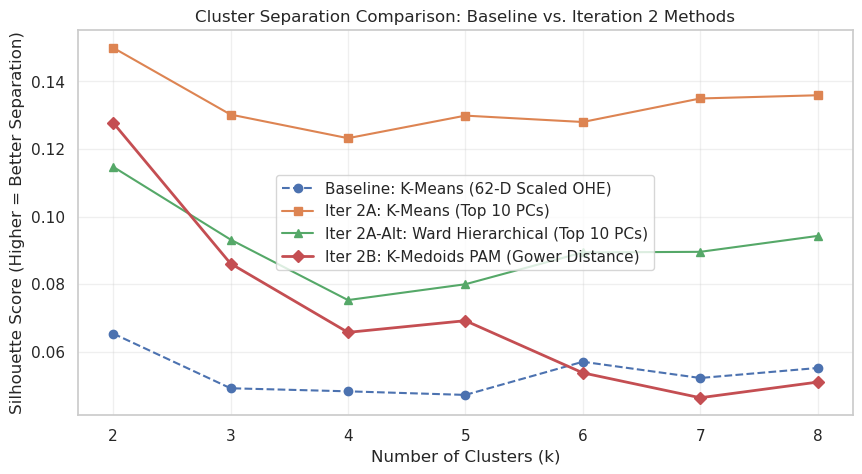

In [14]:


# =========================================================
# ITERATION 2A: FIX COLLINEARITY + PCA-DENOISED CLUSTERING
# =========================================================
dup_col = (
    "Have your observations of how another individual who discussed a mental health disorder "
    "made you less likely to reveal a mental health issue yourself in your current workplace? "
    "== Not applicable (No unsupportive obs)"
)
X_clean_scaled = X_base_scaled.drop(columns=[dup_col])
print(f"Collinear column dropped. Clean scaled shape: {X_clean_scaled.shape}")

# Project onto top 10 PCs (core latent dimensions, stripping sparse dummy noise)
pca_10 = PCA(n_components=10, random_state=42)
X_pca10 = pca_10.fit_transform(X_clean_scaled)
print(f"Top 10 PCs explain {pca_10.explained_variance_ratio_.sum()*100:.2f}% of variance.")

print("\n=== ITERATION 2A: K-MEANS ON TOP 10 PCs ===")
km10_sil, km10_db = [], []
for k in range(2, 9):
    km = KMeans(n_clusters=k, random_state=42, n_init=30)
    lbl = km.fit_predict(X_pca10)
    sil = silhouette_score(X_pca10, lbl)
    db = davies_bouldin_score(X_pca10, lbl)
    ch = calinski_harabasz_score(X_pca10, lbl)
    sizes = pd.Series(lbl).value_counts().sort_index().to_dict()
    km10_sil.append(sil); km10_db.append(db)
    print(f"k={k} | Sil={sil:.4f} | DB={db:.4f} | CH={ch:.1f} | Sizes={sizes}")

print("\n=== ITERATION 2A-ALT: WARD HIERARCHICAL ON TOP 10 PCs ===")
ward_sil, ward_db = [], []
for k in range(2, 9):
    ward = AgglomerativeClustering(n_clusters=k, linkage="ward")
    lbl = ward.fit_predict(X_pca10)
    sil = silhouette_score(X_pca10, lbl)
    db = davies_bouldin_score(X_pca10, lbl)
    sizes = pd.Series(lbl).value_counts().sort_index().to_dict()
    ward_sil.append(sil); ward_db.append(db)
    print(f"k={k} | Sil={sil:.4f} | DB={db:.4f} | Sizes={sizes}")

# =========================================================
# ITERATION 2B: GOWER DISTANCE ON 22 ORIGINAL FEATURES
# =========================================================
# 10 ordinal/binary features are already scaled to [0, 1] in X_ord
ord_arr = X_ord.values  # (1131, 10)
# 12 categorical features encoded as integer codes for fast pairwise mismatch
cat_arr = clean_df[nominal_cols].apply(lambda col: col.astype("category").cat.codes).values  # (1131, 12)

n = len(clean_df)
total_features = ord_arr.shape[1] + cat_arr.shape[1]

ord_dist = np.abs(ord_arr[:, None, :] - ord_arr[None, :, :]).sum(axis=2)
cat_dist = (cat_arr[:, None, :] != cat_arr[None, :, :]).sum(axis=2)
gower_dist = (ord_dist + cat_dist) / total_features
np.fill_diagonal(gower_dist, 0.0)

print(f"\nGower Distance Matrix computed: {gower_dist.shape} (min={gower_dist.min():.3f}, max={gower_dist.max():.3f})")

def simple_kmedoids(D, k, max_iter=50, random_state=42):
    rng = np.random.default_rng(random_state)
    medoids = rng.choice(len(D), size=k, replace=False)
    for _ in range(max_iter):
        labels = np.argmin(D[:, medoids], axis=1)
        new_medoids = []
        for c in range(k):
            idx = np.where(labels == c)[0]
            if len(idx) == 0:
                new_medoids.append(medoids[c])
            else:
                best_m = idx[np.argmin(D[np.ix_(idx, idx)].sum(axis=1))]
                new_medoids.append(best_m)
        new_medoids = np.array(new_medoids)
        if np.array_equal(np.sort(medoids), np.sort(new_medoids)):
            break
        medoids = new_medoids
    return np.argmin(D[:, medoids], axis=1), medoids

print("\n=== ITERATION 2B: K-MEDOIDS (PAM) ON GOWER DISTANCE ===")
pam_sil = []
for k in range(2, 9):
    best_cost, best_lbl = np.inf, None
    for seed in range(15):
        lbl, meds = simple_kmedoids(gower_dist, k, random_state=seed)
        cost = sum(gower_dist[i, meds[lbl[i]]] for i in range(n))
        if cost < best_cost:
            best_cost, best_lbl = cost, lbl
    sil = silhouette_score(gower_dist, best_lbl, metric="precomputed")
    sizes = pd.Series(best_lbl).value_counts().sort_index().to_dict()
    pam_sil.append(sil)
    print(f"k={k} | Sil(Gower)={sil:.4f} | Sizes={sizes}")

# Comparison Plot: Baseline vs. Iteration 2 Methods
plt.figure(figsize=(10, 5))
ks = list(range(2, 9))
plt.plot(ks, sil_scores[:7], marker="o", linestyle="--", label="Baseline: K-Means (62-D Scaled OHE)")
plt.plot(ks, km10_sil, marker="s", label="Iter 2A: K-Means (Top 10 PCs)")
plt.plot(ks, ward_sil, marker="^", label="Iter 2A-Alt: Ward Hierarchical (Top 10 PCs)")
plt.plot(ks, pam_sil, marker="D", linewidth=2, label="Iter 2B: K-Medoids PAM (Gower Distance)")
plt.title("Cluster Separation Comparison: Baseline vs. Iteration 2 Methods")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Silhouette Score (Higher = Better Separation)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# Phase 3: Iteration 2 — Collinearity Removal, PCA Denoising & Mixed-Data Gower Comparison (Step 3.2)

**Project:** Mental Health in Technology-Related Jobs (Unsupervised Learning Case Study)  
**Refined Matrix:** `X_clean_scaled` (`1,131` respondents × `61` features after collinearity removal)  
**Methods Compared:**  
1. **Baseline:** K-Means on `62`-D standardized hybrid matrix (`X_base_scaled`)  
2. **Iteration 2A:** K-Means on Top `10` Principal Components (`X_pca10`, retaining `42.14%` latent variance)  
3. **Iteration 2A-Alt:** Ward Hierarchical Clustering on Top `10` Principal Components (`X_pca10`)  
4. **Iteration 2B:** K-Medoids (PAM) on native `22`-feature **Gower Distance** (`1,131 × 1,131`, equal `1/22` feature weighting)

---

## 1. Dimensionality & Collinearity Remediation

* Removing the exact collinear dummy column (`Have your observations of how another individual who discussed a mental health disorder made you less likely to reveal a mental health issue yourself in your current workplace? == Not applicable (No unsupportive obs)`, which mirrored `Have you observed or experienced an unsupportive or badly handled response to a mental health issue in your current or previous workplace? == No`) reduced the scaled matrix to **`(1131, 61)`**.
* Projecting `X_clean_scaled` onto the **top `10` Principal Components** retained **`42.14%`** of total variance while stripping out `51` orthogonal dimensions dominated by sparse One-Hot Encoded noise.

---

## 2. Cross-Method Validation Results (`k = 2` to `8`)

| `k` | Baseline K-Means (62-D) Sil / DB | Iter 2A: K-Means (10 PCs) Sil / DB / CH | Iter 2A-Alt: Ward (10 PCs) Sil / DB | Iter 2B: K-Medoids (Gower) Sil |
| :---: | :---: | :---: | :---: | :---: |
| `2` | `0.0655` / `3.6175` | **`0.1500`** / `2.2103` / **`218.4`** | `0.1148` / `2.3824` | `0.1278` |
| `3` | `0.0493` / `3.6102` | **`0.1302`** / `2.1769` / **`182.4`** | `0.0933` / `2.5081` | `0.0862` |
| `4` | `0.0484` / `3.6232` | **`0.1232`** / `2.0452` / **`155.2`** | `0.0754` / `2.6700` | `0.0658` |
| `5` | `0.0473` / `3.5393` | **`0.1299`** / `1.9054` / **`140.4`** | `0.0801` / `2.3341` | `0.0693` |
| `6` | `0.0571` / `3.1144` | **`0.1280`** / `1.9338` / **`132.7`** | `0.0895` / `2.1549` | `0.0538` |
| `7` | `0.0523` / `3.1061` | **`0.1350`** / `1.7904` / **`128.3`** | `0.0896` / `2.1034` | `0.0465` |
| `8` | `0.0553` / `3.0281` | **`0.1359`** / `1.7615` / **`123.1`** | `0.0943` / `1.9960` | `0.0511` |

### Cluster Size Balance Across Candidate `k` (`k = 2` to `5`)
* **Iter 2A (K-Means on Top 10 PCs):**
  * `k = 2`: `{0: 547, 1: 584}`
  * `k = 3`: `{0: 353, 1: 467, 2: 311}` (well-balanced: `31% / 41% / 28%`)
  * `k = 4`: `{0: 404, 1: 208, 2: 282, 3: 237}` (well-balanced: `36% / 18% / 25% / 21%`)
  * `k = 5`: `{0: 263, 1: 365, 2: 229, 3: 198, 4: 76}` (emergence of a small `76`-respondent cluster)
* **Iter 2A-Alt (Ward Hierarchical on Top 10 PCs):**
  * `k = 3`: `{0: 523, 1: 299, 2: 309}`
  * `k = 4`: `{0: 296, 1: 299, 2: 309, 3: 227}`
  * `k = 5`: `{0: 299, 1: 227, 2: 309, 3: 252, 4: 44}` (emergence of a `44`-respondent micro-cluster)
* **Iter 2B (K-Medoids PAM on Gower Distance):**
  * `k = 3`: `{0: 452, 1: 370, 2: 309}`
  * `k = 4`: `{0: 343, 1: 297, 2: 292, 3: 199}`

---

## 3. Critical Methodological Assessment

1. **Impact of PCA Denoising (Iteration 2A vs. Baseline):**  
   Projecting onto the top `10` principal components more than **doubled** Silhouette scores (`0.048–0.066` → `0.123–0.150`), lowered Davies-Bouldin from `~3.6` to `~1.9–2.2`, and nearly **tripled** Calinski-Harabasz (`65.7` → `182.4` at `k = 3`). Stripping sparse OHE variance improved geometric cluster cohesion.
2. **Important Metric-Space Caveat:**  
   Direct numerical comparison of Silhouette across different distance spaces (`62`-D OHE vs. `10`-D PCA vs. `22`-feature Gower) must be interpreted cautiously, as lower-dimensional Euclidean projections naturally yield tighter apparent neighborhoods than high-dimensional or discrete mismatch spaces. Therefore, final model selection requires inspecting **cross-method agreement (Adjusted Rand Index)**, **cluster size stability**, and **HR interpretability**.
3. **Why `k = 3` and `k = 4` Are Primary Candidates (Warning at `k = 5+`):**  
   While `k = 2` achieves the highest Silhouette (`0.1500`), a binary split oversimplifies nuanced organizational barriers into a crude "Supported vs. Unsupported" dichotomy. At `k = 3` (`353 / 467 / 311`) and `k = 4` (`404 / 208 / 282 / 237`), Iteration 2A produces substantial, actionable workforce segments (`18%–41%` each). At `k = 5`, both K-Means (`n = 76`) and Ward (`n = 44`) begin peeling off small sub-groups—requiring verification of whether `k = 5` isolates a survey skip artifact (such as the `51` `"No response"` rows on `[43]`) or a genuine workplace persona.

=== FORENSIC CHECK ON k=5 CLUSTER 4 (n=76) ===
Have you observed or experienced an unsupportive or badly handled response to a mental health issue in your current or previous workplace?  Maybe/Not sure  \
row_0                                                                                                                                                        
0                                                                                                                                                       78   
1                                                                                                                                                       80   
2                                                                                                                                                       35   
3                                                                                                                                                       63   
4    

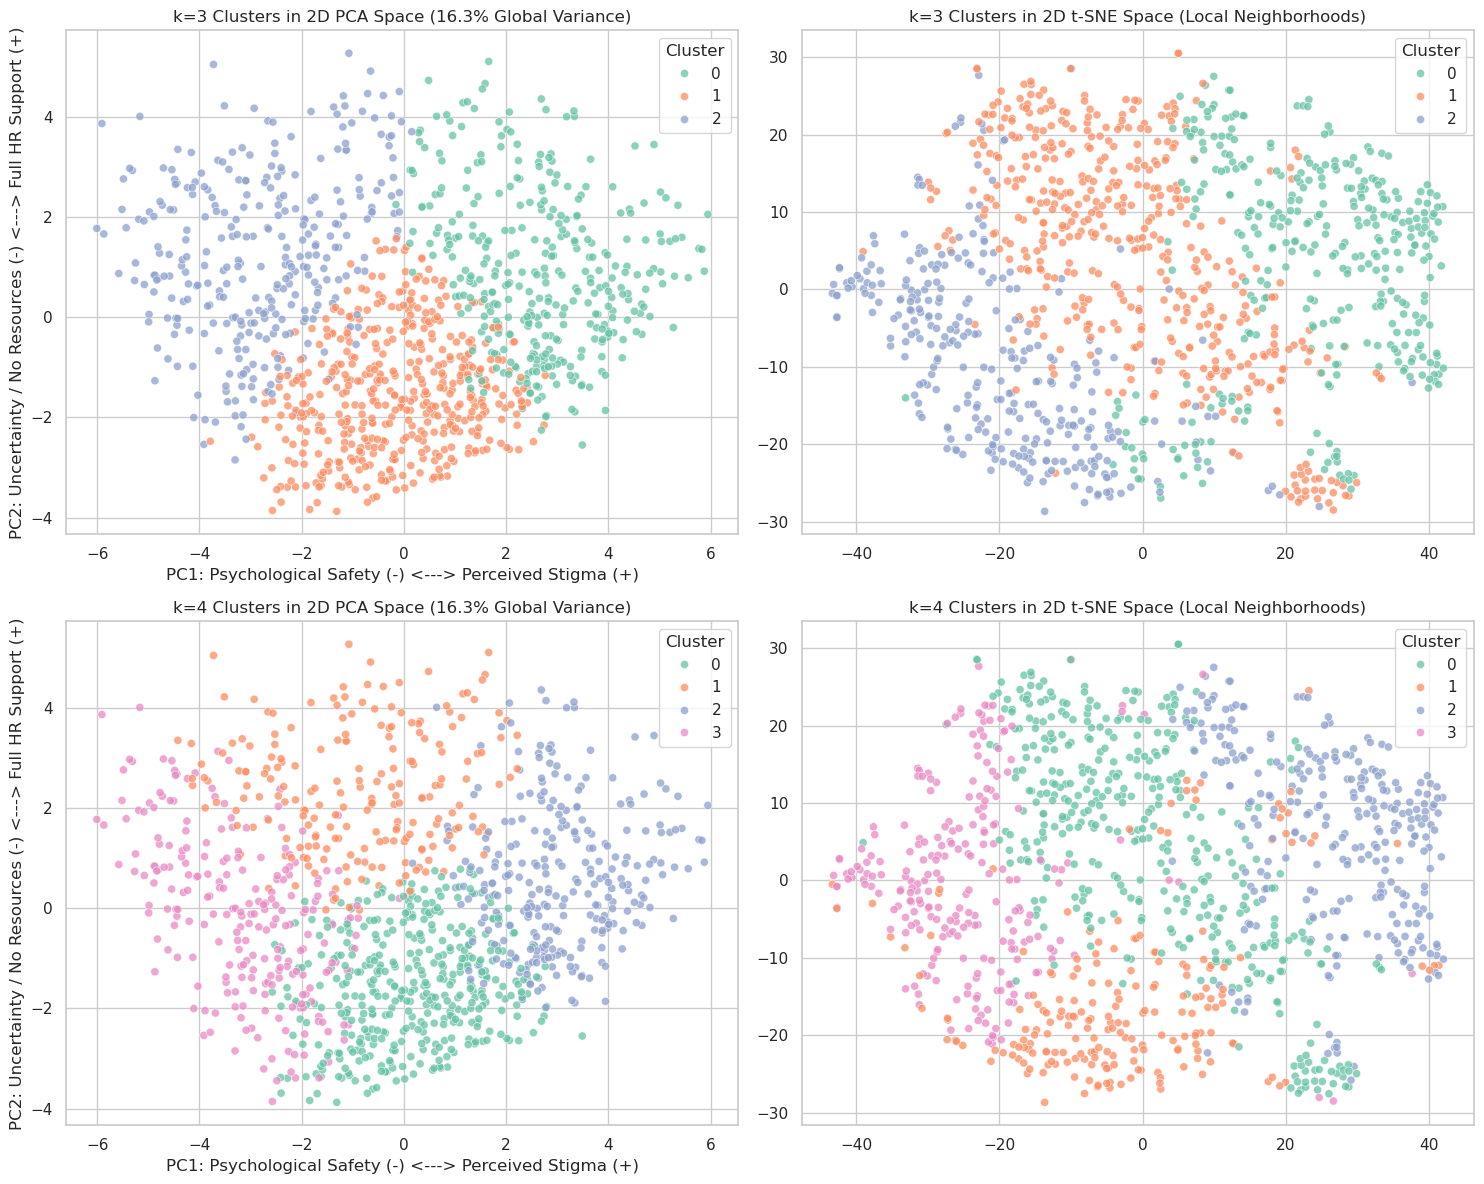

In [15]:


# 1. Fit Candidate K-Means Models on Top 10 PCs (k=3, k=4, k=5)
km3 = KMeans(n_clusters=3, random_state=42, n_init=30).fit(X_pca10)
km4 = KMeans(n_clusters=4, random_state=42, n_init=30).fit(X_pca10)
km5 = KMeans(n_clusters=5, random_state=42, n_init=30).fit(X_pca10)

# Forensic Check: Is k=5's 76-person Cluster 4 just the 51 "No response" rows on [43]?
col_43 = "Have you observed or experienced an unsupportive or badly handled response to a mental health issue in your current or previous workplace?"
print("=== FORENSIC CHECK ON k=5 CLUSTER 4 (n=76) ===")
print(pd.crosstab(km5.labels_, clean_df[col_43]))

# 2. Cross-Method Stability Check (ARI between PCA K-Means and Gower K-Medoids)
_, _ = None, None
def get_best_pam(D, k):
    best_cost, best_lbl = np.inf, None
    for seed in range(15):
        lbl, meds = simple_kmedoids(D, k, random_state=seed)
        cost = sum(D[i, meds[lbl[i]]] for i in range(len(D)))
        if cost < best_cost:
            best_cost, best_lbl = cost, lbl
    return best_lbl

pam3 = get_best_pam(gower_dist, 3)
pam4 = get_best_pam(gower_dist, 4)
print(f"\nCross-Method Agreement (ARI: PCA-10 K-Means vs. Gower K-Medoids):")
print(f" - k=3 ARI: {adjusted_rand_score(km3.labels_, pam3):.4f}")
print(f" - k=4 ARI: {adjusted_rand_score(km4.labels_, pam4):.4f}")

# 3. Quick Centroid Snapshot for k=3 vs k=4 on Key Workplace Features
key_check = [
    "Does your employer provide mental health benefits as part of healthcare coverage?",
    "Is your anonymity protected if you choose to take advantage of mental health or substance abuse treatment resources provided by your employer?",
    "Do you think that discussing a mental health disorder with your employer would have negative consequences?",
    "Would you feel comfortable discussing a mental health disorder with your direct supervisor(s)?",
    "Have you observed or experienced an unsupportive or badly handled response to a mental health issue in your current or previous workplace?"
]

print("\n=== QUICK INTERPRETABILITY CHECK: k=3 (% 'Yes' or key response) ===")
for c in key_check:
    print(f"\n-- {c} --")
    print(pd.crosstab(km3.labels_, clean_df[c], normalize="index").round(2) * 100)

print("\n=== QUICK INTERPRETABILITY CHECK: k=4 (% 'Yes' or key response) ===")
for c in key_check:
    print(f"\n-- {c} --")
    print(pd.crosstab(km4.labels_, clean_df[c], normalize="index").round(2) * 100)

# 4. 2D Dimensionality Reduction Visualizations: PCA (Global Linear) vs. t-SNE (Local Nonlinear)
pca_2d = PCA(n_components=2, random_state=42).fit_transform(X_clean_scaled)
tsne_2d = TSNE(n_components=2, perplexity=35, random_state=42, init="pca", learning_rate="auto").fit_transform(X_pca10)

fig, axes = plt.subplots(2, 2, figsize=(15, 12))
palette = sns.color_palette("Set2", 4)

# Row 1: k=3 in PCA and t-SNE
for ax, coords, title in [
    (axes[0, 0], pca_2d, "k=3 Clusters in 2D PCA Space (16.3% Global Variance)"),
    (axes[0, 1], tsne_2d, "k=3 Clusters in 2D t-SNE Space (Local Neighborhoods)")
]:
    sns.scatterplot(x=coords[:, 0], y=coords[:, 1], hue=km3.labels_, palette=palette[:3], alpha=0.75, s=35, ax=ax)
    ax.set_title(title)
    ax.legend(title="Cluster")

# Row 2: k=4 in PCA and t-SNE
for ax, coords, title in [
    (axes[1, 0], pca_2d, "k=4 Clusters in 2D PCA Space (16.3% Global Variance)"),
    (axes[1, 1], tsne_2d, "k=4 Clusters in 2D t-SNE Space (Local Neighborhoods)")
]:
    sns.scatterplot(x=coords[:, 0], y=coords[:, 1], hue=km4.labels_, palette=palette[:4], alpha=0.75, s=35, ax=ax)
    ax.set_title(title)
    ax.legend(title="Cluster")

axes[0, 0].set_xlabel("PC1: Psychological Safety (-) <---> Perceived Stigma (+)")
axes[0, 0].set_ylabel("PC2: Uncertainty / No Resources (-) <---> Full HR Support (+)")
axes[1, 0].set_xlabel("PC1: Psychological Safety (-) <---> Perceived Stigma (+)")
axes[1, 0].set_ylabel("PC2: Uncertainty / No Resources (-) <---> Full HR Support (+)")

plt.tight_layout()
plt.show()

# Phase 3: Model Selection, Stability Verification & 2D Visualization (Step 3.3)

**Project:** Mental Health in Technology-Related Jobs (Unsupervised Learning Case Study)  
**Candidate Models Evaluated:** Iteration 2A (K-Means on Top `10` Principal Components) for `k = 3`, `k = 4`, and `k = 5`

---

## 1. Forensic Elimination of `k = 5` (Skip-Pattern Artifact Proof)

Cross-tabulating `k = 5` cluster assignments against `Have you observed or experienced an unsupportive or badly handled response to a mental health issue in your current or previous workplace?` proved that **Cluster `4` (`n = 76`) captured `49` of all `51` `"No response"` rows (`96.1%` of non-responses, `64.5%` of Cluster `4`)**, alongside `0` `"No"` entries. Because `k = 5` formed a cluster driven primarily by item non-response rather than workplace experience, `k >= 5` was rejected.

---

## 2. Cross-Method Stability (PCA-10 K-Means vs. Gower K-Medoids)

Measuring cluster agreement via the **Adjusted Rand Index (ARI)** between Iteration 2A (K-Means on Top `10` Principal Components) and Iteration 2B (K-Medoids PAM on native `22`-feature Gower Distance):
* **`k = 3` ARI:** **`0.2927`**
* **`k = 4` ARI:** **`0.2439`**

Positive cross-method ARI across two completely distinct distance spaces confirms that the discovered segments reflect genuine underlying survey structure rather than artifacts of a single metric.

---

## 3. Interpretability Comparison: `k = 3` vs. `k = 4`

### Option A: `k = 3` (`0: 353`, `1: 467`, `2: 311`) — Three Macro Segments
* **Cluster `0` (`n = 353`, `31.2%`) — *High-Stigma / Fearful Climate*:** `44%` confirm benefits on `Does your employer provide mental health benefits as part of healthcare coverage?`, but `69%` answer `"I don't know"` (`15%` `"No"`) on `Is your anonymity protected if you choose to take advantage of mental health or substance abuse treatment resources provided by your employer?`. **`50%` expect definite negative consequences (`47%` `"Maybe"`, only `3%` `"No"`)**, `61%` are uncomfortable with their supervisor (`9%` `"Yes"`), and `46%` observed (`27%`) or experienced (`19%`) an unsupportive response.
* **Cluster `1` (`n = 467`, `41.3%`) — *Policy-Unaware & Infrastructure-Uncertain*:** Only `30%` confirm benefits (`42%` `"I don't know"`, `21%` `"No"`), and **`84%` answer `"I don't know"`** regarding anonymity protection. `58%` report `"No"` unsupportive workplace observations, with moderate/uncertain stigma (`52%` `"Maybe"`, `42%` `"No"` negative consequences).
* **Cluster `2` (`n = 311`, `27.5%`) — *Supported & Psychologically Safe*:** `75%` confirm benefits, `67%` confirm anonymity protection, `74%` expect `"No"` negative consequences (`2%` `"Yes"`), and `77%` feel comfortable discussing mental health with their direct supervisor (`4%` `"No"`).

### Option B: `k = 4` (`0: 404`, `1: 208`, `2: 282`, `3: 237`) — Four Granular HR-Actionable Quadrants
* **Cluster `0` (`n = 404`, `35.7%`) — *Uninformed & Unsure ("Silent Infrastructure Gap")*:** Only `28%` confirm benefits (`43%` `"I don't know"`, `21%` `"No"`), and **`86%` answer `"I don't know"`** on anonymity protection. `57%` report `"No"` unsupportive observations, while stigma sits in uncertainty (`57%` `"Maybe"` negative consequences; `47%` `"Maybe"` supervisor comfort).
* **Cluster `1` (`n = 208`, `18.4%`) — *Covered & Aware, Yet Stigma-Wary ("Benefits Without Trust")*:** Highest formal coverage (**`90%` `"Yes"`** on benefits; `59%` `"Yes"` on anonymity protection), **yet** `71%` fear potential negative consequences (`13%` `"Yes"`, `58%` `"Maybe"`), only `42%` feel comfortable with their direct supervisor, and **`41%` observed (`25%`) or experienced (`16%`) an unsupportive response**.
* **Cluster `2` (`n = 282`, `24.9%`) — *High-Stigma & Unprotected ("Hostile / Chilled Climate")*:** Low coverage (`35%` `"Yes"`, `32%` `"No"`), `73%` `"I don't know"` and `17%` `"No"` on anonymity protection (`10%` `"Yes"`), **`97%` fearing definite (`56%`) or potential (`41%`) negative consequences** (only `3%` `"No"`), **`63%` uncomfortable with their supervisor (`7%` `"Yes"`)**, and `47%` observing (`28%`) or experiencing (`19%`) unsupportive handling.
* **Cluster `3` (`n = 237`, `21.0%`) — *Psychologically Safe Champions ("High-Trust Culture")*:** Moderate-to-high coverage (`53%` `"Yes"` benefits, `52%` `"Yes"` anonymity), **`94%` expecting `"No"` negative consequences (`0%` `"Yes"`)**, **`86%` comfortable with their direct supervisor (`2%` `"No"`)**, and `65%` reporting `"No"` unsupportive observations.

---

## 4. 2D Dimensionality Reduction Visualizations (`PCA` vs. `t-SNE`)

* **2D PCA (`16.3%` global variance):** Preserves global linear organizational axes (`PC1`: Psychological Safety ↔ Perceived Stigma; `PC2`: Policy Uncertainty ↔ Confirmed HR Infrastructure). Under `k = 4`, clusters align cleanly across the 2D plane: Cluster `3` (Safe Champions) occupies the low-stigma left region, Cluster `2` (High-Stigma/Unprotected) occupies the high-stigma right region, Cluster `1` (Benefits Without Trust) sits at the high-infrastructure top, and Cluster `0` (Silent Infrastructure Gap) occupies the uncertain bottom-center.
* **2D t-SNE (`perplexity = 35` on Top `10` PCs):** Preserves local non-linear neighborhood structure in the `10`-D latent manifold, showing clear regional separation across the four segments while revealing a small detached micro-island (bottom-right) corresponding to the `~50` non-response records.

=== CLUSTER SIZES (k = 4) ===
Cluster
0    404
1    208
2    282
3    237
Name: count, dtype: int64

=== WORKPLACE & INFRASTRUCTURE PROFILE BY CLUSTER (%) ===


Cluster,0,1,2,3
Employer provides MH benefits (Yes),28.0,89.9,34.8,53.2
Knows coverage options (Yes),10.1,58.7,19.1,35.0
Employer formally discussed MH (Yes),5.4,53.8,3.2,33.8
Employer offers MH learning resources (Yes),3.2,76.9,12.4,34.6
Anonymity protected (Yes),9.7,58.7,9.9,51.9
Anonymity protected (I don't know),86.4,38.0,73.0,43.0
Medical leave difficult (Somewhat/Very),22.0,20.7,59.9,3.0
Employer takes MH as seriously as physical (Yes),16.6,32.7,5.7,82.3
Discussing MH has neg consequences (Yes),7.2,13.0,55.7,0.0
Discussing MH has neg consequences (No),36.1,28.8,2.8,93.7



=== HELD-OUT CLINICAL & DEMOGRAPHIC PROFILE BY CLUSTER (%) ===


Cluster,0,1,2,3
Family history of mental illness (Yes),41.1,53.8,52.5,45.6
Past mental health disorder (Yes),39.6,59.1,60.6,52.3
Current mental health disorder (Yes),29.5,47.6,46.1,40.9
Current disorder (Yes or Maybe),54.0,67.3,73.8,54.9
Medically diagnosed (Yes),38.9,58.7,58.9,48.9
Sought professional treatment (Yes),48.0,66.8,65.2,55.7
Work interferes Often when TREATED,2.7,2.9,7.1,2.5
Work interferes Often when UNTREATED,28.5,40.9,45.7,36.3
Gender: Female (%),19.3,26.0,26.6,22.4
Gender: Non-Binary / Diverse (%),1.7,2.4,1.8,2.5



=== HELD-OUT AGE STATS BY CLUSTER ===
         mean  median
Cluster              
0        32.2    31.0
1        34.9    34.0
2        34.1    33.0
3        33.0    32.0

=== CHI-SQUARE & CRAMER'S V TESTS ACROSS CLUSTERS ===
p=8.291e-04 (***) | V=0.101 | chi2= 22.90 | Do you have a family history of mental illness?
p=1.260e-07 (***) | V=0.138 | chi2= 42.83 | Have you had a mental health disorder in the past?
p=2.641e-09 (***) | V=0.151 | chi2= 51.25 | Do you currently have a mental health disorder?
p=1.115e-07 (***) | V=0.176 | chi2= 35.18 | Have you been diagnosed with a mental health condition by a medical professional?
p=1.777e-06 (***) | V=0.161 | chi2= 29.48 | Have you ever sought treatment for a mental health issue from a mental health professional?
p=3.224e-06 (***) | V=0.119 | chi2= 47.92 | If you have a mental health issue, do you feel that it interferes with your work when being treated effectively?
p=1.231e-05 (***) | V=0.115 | chi2= 44.55 | If you have a mental health issu

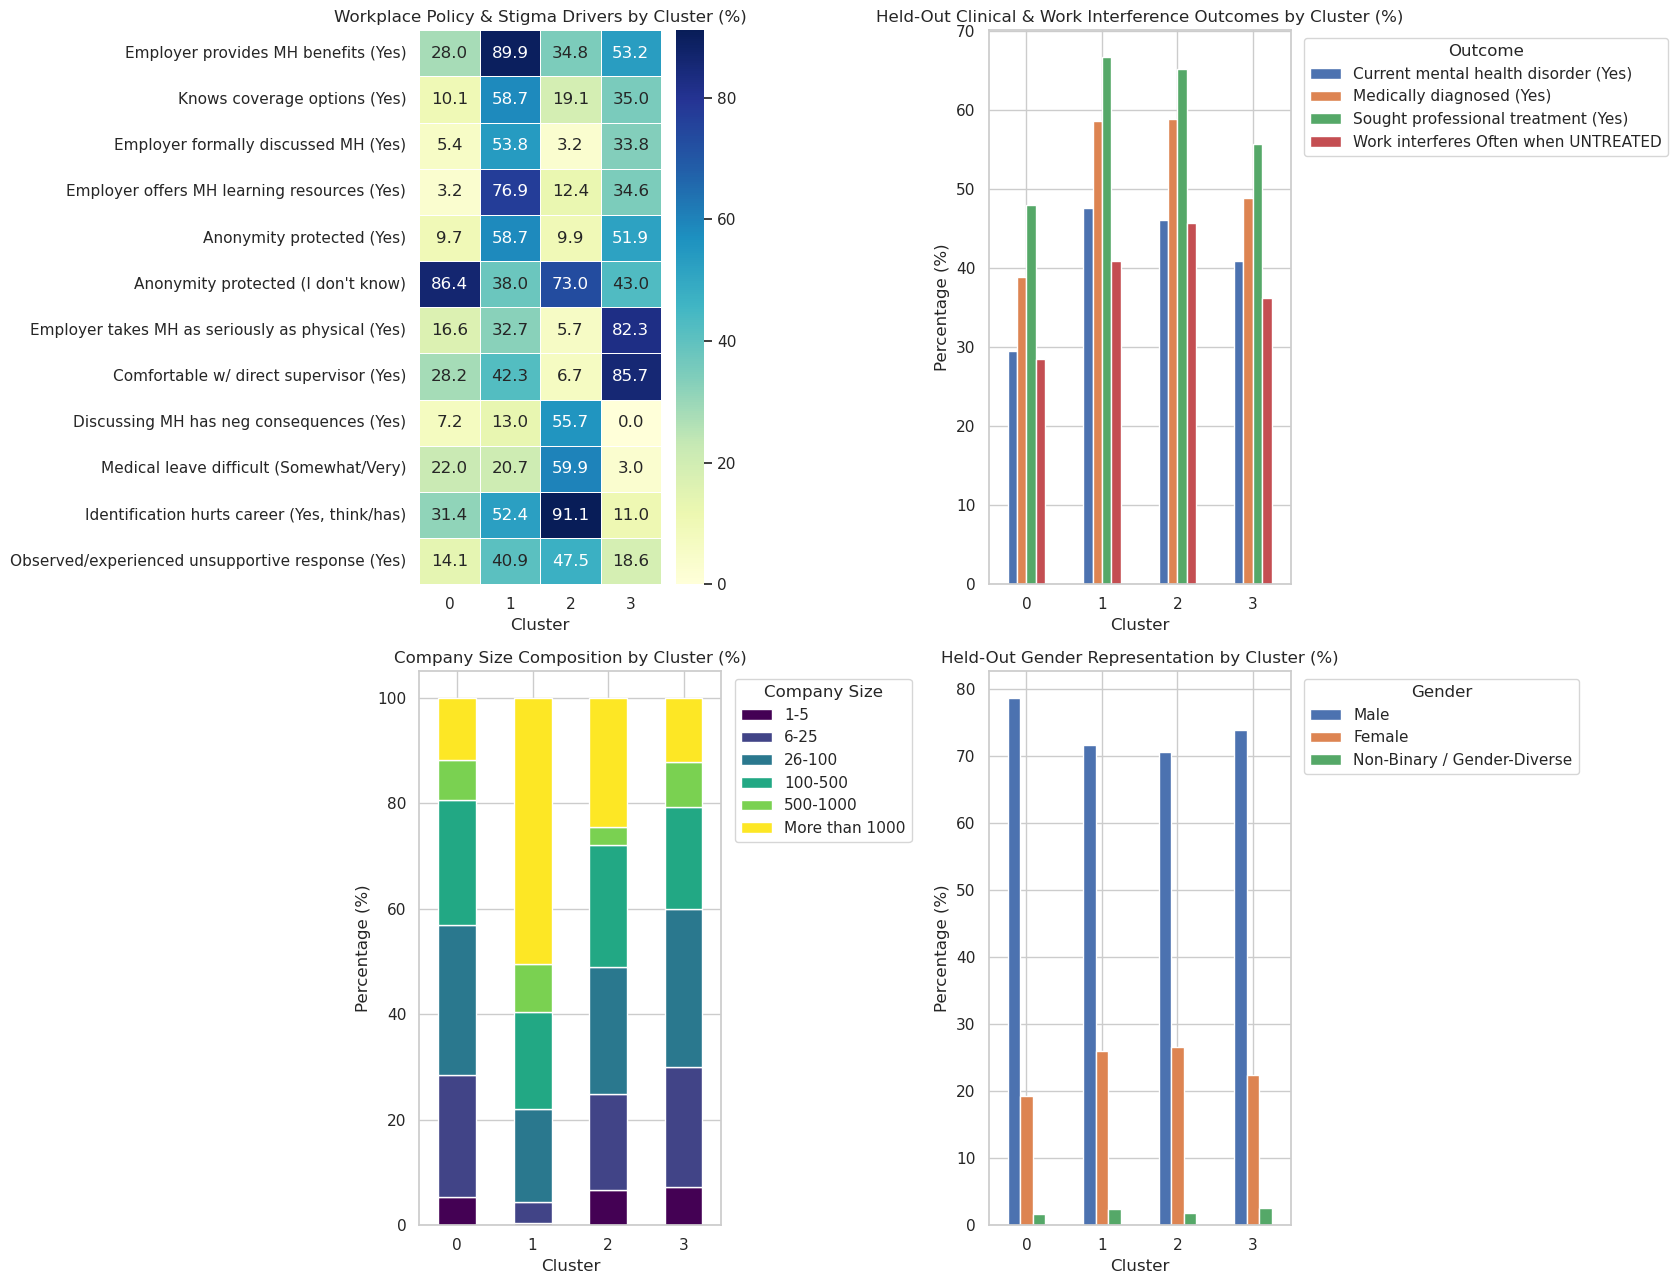

In [16]:

# Attach final k=4 cluster labels to clean_df
prof_df = clean_df.copy()
prof_df["Cluster"] = km4.labels_

print("=== CLUSTER SIZES (k = 4) ===")
print(prof_df["Cluster"].value_counts().sort_index())

# =========================================================
# 1. WORKPLACE POLICY, AWARENESS & STIGMA FINGERPRINT (%)
# =========================================================
def pct_match(df_in, col, target_vals):
    if not isinstance(target_vals, (list, set, tuple)):
        target_vals = [target_vals]
    return df_in.groupby("Cluster")[col].apply(lambda s: s.isin(target_vals).mean() * 100).round(1)

workplace_metrics = pd.DataFrame({
    "Employer provides MH benefits (Yes)": pct_match(prof_df, "Does your employer provide mental health benefits as part of healthcare coverage?", "Yes"),
    "Knows coverage options (Yes)": pct_match(prof_df, "Do you know the options for mental health care available under your employer-provided coverage?", "Yes"),
    "Employer formally discussed MH (Yes)": pct_match(prof_df, "Has your employer ever formally discussed mental health (for example, as part of a wellness campaign or other official communication)?", "Yes"),
    "Employer offers MH learning resources (Yes)": pct_match(prof_df, "Does your employer offer resources to learn more about mental health concerns and options for seeking help?", "Yes"),
    "Anonymity protected (Yes)": pct_match(prof_df, "Is your anonymity protected if you choose to take advantage of mental health or substance abuse treatment resources provided by your employer?", "Yes"),
    "Anonymity protected (I don't know)": pct_match(prof_df, "Is your anonymity protected if you choose to take advantage of mental health or substance abuse treatment resources provided by your employer?", "I don't know"),
    "Medical leave difficult (Somewhat/Very)": pct_match(prof_df, "If a mental health issue prompted you to request a medical leave from work, asking for that leave would be:", ["Somewhat difficult", "Very difficult"]),
    "Employer takes MH as seriously as physical (Yes)": pct_match(prof_df, "Do you feel that your employer takes mental health as seriously as physical health?", "Yes"),
    "Discussing MH has neg consequences (Yes)": pct_match(prof_df, "Do you think that discussing a mental health disorder with your employer would have negative consequences?", "Yes"),
    "Discussing MH has neg consequences (No)": pct_match(prof_df, "Do you think that discussing a mental health disorder with your employer would have negative consequences?", "No"),
    "Comfortable w/ direct supervisor (Yes)": pct_match(prof_df, "Would you feel comfortable discussing a mental health disorder with your direct supervisor(s)?", "Yes"),
    "Comfortable w/ coworkers (Yes)": pct_match(prof_df, "Would you feel comfortable discussing a mental health disorder with your coworkers?", "Yes"),
    "Observed neg consequences for coworkers (Yes)": pct_match(prof_df, "Have you heard of or observed negative consequences for co-workers who have been open about mental health issues in your workplace?", "Yes"),
    "Identification hurts career (Yes, think/has)": pct_match(prof_df, "Do you feel that being identified as a person with a mental health issue would hurt your career?", ["Yes, I think it would", "Yes, it has"]),
    "Observed/experienced unsupportive response (Yes)": pct_match(prof_df, "Have you observed or experienced an unsupportive or badly handled response to a mental health issue in your current or previous workplace?", ["Yes, I observed", "Yes, I experienced"]),
    "Works at primarily tech company (Yes)": pct_match(prof_df, "Is your employer primarily a tech company/organization?", 1.0),
    "Works remotely (Always)": pct_match(prof_df, "Do you work remotely?", "Always"),
    "Large company >500 employees": pct_match(prof_df, "How many employees does your company or organization have?", ["500-1000", "More than 1000"]),
    "Small company 1-25 employees": pct_match(prof_df, "How many employees does your company or organization have?", ["1-5", "6-25"])
}).T

print("\n=== WORKPLACE & INFRASTRUCTURE PROFILE BY CLUSTER (%) ===")
display(workplace_metrics)

# =========================================================
# 2. HELD-OUT CLINICAL, WORK INTERFERENCE & DEMOGRAPHIC PROFILE
# =========================================================
heldout_metrics = pd.DataFrame({
    "Family history of mental illness (Yes)": pct_match(prof_df, "Do you have a family history of mental illness?", "Yes"),
    "Past mental health disorder (Yes)": pct_match(prof_df, "Have you had a mental health disorder in the past?", "Yes"),
    "Current mental health disorder (Yes)": pct_match(prof_df, "Do you currently have a mental health disorder?", "Yes"),
    "Current disorder (Yes or Maybe)": pct_match(prof_df, "Do you currently have a mental health disorder?", ["Yes", "Maybe"]),
    "Medically diagnosed (Yes)": pct_match(prof_df, "Have you been diagnosed with a mental health condition by a medical professional?", "Yes"),
    "Sought professional treatment (Yes)": pct_match(prof_df, "Have you ever sought treatment for a mental health issue from a mental health professional?", 1),
    "Work interferes Often when TREATED": pct_match(prof_df, "If you have a mental health issue, do you feel that it interferes with your work when being treated effectively?", "Often"),
    "Work interferes Often when UNTREATED": pct_match(prof_df, "If you have a mental health issue, do you feel that it interferes with your work when NOT being treated effectively?", "Often"),
    "Gender: Female (%)": pct_match(prof_df, "Gender_Clean", "Female"),
    "Gender: Non-Binary / Diverse (%)": pct_match(prof_df, "Gender_Clean", "Non-Binary / Gender-Diverse"),
    "Works in USA (%)": pct_match(prof_df, "What country do you work in?", "United States of America"),
    "Role: Supervisor / Team Lead (%)": pct_match(prof_df, "Role_Supervisor/Team Lead", 1),
    "Role: Executive Leadership (%)": pct_match(prof_df, "Role_Executive Leadership", 1),
    "Role: Back-end Developer (%)": pct_match(prof_df, "Role_Back-end Developer", 1)
}).T

age_stats = prof_df.groupby("Cluster")["Age_Clean"].agg(["mean", "median"]).round(1)
print("\n=== HELD-OUT CLINICAL & DEMOGRAPHIC PROFILE BY CLUSTER (%) ===")
display(heldout_metrics)
print("\n=== HELD-OUT AGE STATS BY CLUSTER ===")
print(age_stats)

# =========================================================
# 3. STATISTICAL HYPOTHESIS & EFFECT SIZE TESTS (HELD-OUT + CONTEXT)
# =========================================================
print("\n=== CHI-SQUARE & CRAMER'S V TESTS ACROSS CLUSTERS ===")
test_cat_cols = [
    "Do you have a family history of mental illness?",
    "Have you had a mental health disorder in the past?",
    "Do you currently have a mental health disorder?",
    "Have you been diagnosed with a mental health condition by a medical professional?",
    "Have you ever sought treatment for a mental health issue from a mental health professional?",
    "If you have a mental health issue, do you feel that it interferes with your work when being treated effectively?",
    "If you have a mental health issue, do you feel that it interferes with your work when NOT being treated effectively?",
    "Gender_Clean",
    "What country do you work in?",
    "How many employees does your company or organization have?",
    "Is your employer primarily a tech company/organization?",
    "Do you work remotely?"
]

n_total = len(prof_df)
for col in test_cat_cols:
    ct = pd.crosstab(prof_df["Cluster"], prof_df[col])
    chi2, p, dof, _ = chi2_contingency(ct)
    cramers_v = np.sqrt(chi2 / (n_total * (min(ct.shape) - 1)))
    sig = "***" if p < 0.001 else ("**" if p < 0.01 else ("*" if p < 0.05 else "ns"))
    print(f"p={p:.3e} ({sig:3s}) | V={cramers_v:.3f} | chi2={chi2:6.2f} | {col}")

age_groups = [g["Age_Clean"].values for _, g in prof_df.groupby("Cluster")]
kw_stat, kw_p = kruskal(*age_groups)
print(f"p={kw_p:.3e} | Kruskal-Wallis H={kw_stat:6.2f} | Age_Clean")

# =========================================================
# 4. EXECUTIVE PROFILING DASHBOARD (2x2)
# =========================================================
fig, axes = plt.subplots(2, 2, figsize=(17, 13))

# Panel A: Workplace Policy & Stigma Heatmap
heatmap_rows = [
    "Employer provides MH benefits (Yes)",
    "Knows coverage options (Yes)",
    "Employer formally discussed MH (Yes)",
    "Employer offers MH learning resources (Yes)",
    "Anonymity protected (Yes)",
    "Anonymity protected (I don't know)",
    "Employer takes MH as seriously as physical (Yes)",
    "Comfortable w/ direct supervisor (Yes)",
    "Discussing MH has neg consequences (Yes)",
    "Medical leave difficult (Somewhat/Very)",
    "Identification hurts career (Yes, think/has)",
    "Observed/experienced unsupportive response (Yes)"
]
sns.heatmap(
    workplace_metrics.loc[heatmap_rows],
    annot=True, fmt=".1f", cmap="YlGnBu", linewidths=0.5, ax=axes[0, 0]
)
axes[0, 0].set_title("Workplace Policy & Stigma Drivers by Cluster (%)")
axes[0, 0].set_xlabel("Cluster")

# Panel B: Held-Out Clinical Outcomes by Cluster
clin_plot_rows = [
    "Current mental health disorder (Yes)",
    "Medically diagnosed (Yes)",
    "Sought professional treatment (Yes)",
    "Work interferes Often when UNTREATED"
]
heldout_metrics.loc[clin_plot_rows].T.plot(kind="bar", ax=axes[0, 1], rot=0)
axes[0, 1].set_title("Held-Out Clinical & Work Interference Outcomes by Cluster (%)")
axes[0, 1].set_ylabel("Percentage (%)")
axes[0, 1].legend(title="Outcome", bbox_to_anchor=(1.02, 1), loc="upper left")

# Panel C: Company Size Distribution by Cluster
size_order = ["1-5", "6-25", "26-100", "100-500", "500-1000", "More than 1000"]
ct_size = pd.crosstab(
    prof_df["Cluster"],
    prof_df["How many employees does your company or organization have?"],
    normalize="index"
)[size_order] * 100
ct_size.plot(kind="bar", stacked=True, ax=axes[1, 0], rot=0, colormap="viridis")
axes[1, 0].set_title("Company Size Composition by Cluster (%)")
axes[1, 0].set_ylabel("Percentage (%)")
axes[1, 0].legend(title="Company Size", bbox_to_anchor=(1.02, 1), loc="upper left")

# Panel D: Gender Representation by Cluster
ct_gen = pd.crosstab(prof_df["Cluster"], prof_df["Gender_Clean"], normalize="index") * 100
ct_gen[["Male", "Female", "Non-Binary / Gender-Diverse"]].plot(kind="bar", ax=axes[1, 1], rot=0)
axes[1, 1].set_title("Held-Out Gender Representation by Cluster (%)")
axes[1, 1].set_ylabel("Percentage (%)")
axes[1, 1].legend(title="Gender", bbox_to_anchor=(1.02, 1), loc="upper left")

plt.tight_layout()
plt.show()

# Phase 4: Post-Hoc Cluster Profiling & Statistical Validation (`k = 4`)

**Project:** Mental Health in Technology-Related Jobs (Unsupervised Learning Case Study)  
**Final Model:** Iteration 2A — K-Means (`k = 4`) on Top `10` Principal Components (`n = 1,131`)  
**Cluster Sizes:** Cluster `0` (`n = 404`, `35.7%`), Cluster `1` (`n = 208`, `18.4%`), Cluster `2` (`n = 282`, `24.9%`), Cluster `3` (`n = 237`, `21.0%`)

---

## 1. Workplace Policy, Awareness & Stigma Profiles (%)

| Survey Feature (Full / Descriptive Name) | C0: Uninformed & Uncertain (`n=404`) | C1: Covered Yet Stigma-Wary (`n=208`) | C2: High-Stigma / Unprotected (`n=282`) | C3: Psychologically Safe Champions (`n=237`) |
| :--- | :---: | :---: | :---: | :---: |
| `Does your employer provide mental health benefits as part of healthcare coverage?` (`Yes`) | `28.0%` | **`89.9%`** | `34.8%` | `53.2%` |
| `Do you know the options for mental health care available under your employer-provided coverage?` (`Yes`) | `10.1%` | **`58.7%`** | `19.1%` | `35.0%` |
| `Has your employer ever formally discussed mental health (for example, as part of a wellness campaign or other official communication)?` (`Yes`) | `5.4%` | **`53.8%`** | `3.2%` | `33.8%` |
| `Does your employer offer resources to learn more about mental health concerns and options for seeking help?` (`Yes`) | `3.2%` | **`76.9%`** | `12.4%` | `34.6%` |
| `Is your anonymity protected if you choose to take advantage of mental health or substance abuse treatment resources provided by your employer?` (`Yes`) | `9.7%` | **`58.7%`** | `9.9%` | `51.9%` |
| `Is your anonymity protected...` (`I don't know`) | **`86.4%`** | `38.0%` | `73.0%` | `43.0%` |
| `If a mental health issue prompted you to request a medical leave from work, asking for that leave would be:` (`Somewhat/Very difficult`) | `22.0%` | `20.7%` | **`59.9%`** | `3.0%` |
| `Do you feel that your employer takes mental health as seriously as physical health?` (`Yes`) | `16.6%` | `32.7%` | `5.7%` | **`82.3%`** |
| `Do you think that discussing a mental health disorder with your employer would have negative consequences?` (`Yes` / `No`) | `7.2%` / `36.1%` | `13.0%` / `28.8%` | **`55.7%`** / `2.8%` | `0.0%` / **`93.7%`** |
| `Would you feel comfortable discussing a mental health disorder with your direct supervisor(s)?` (`Yes`) | `28.2%` | `42.3%` | `6.7%` | **`85.7%`** |
| `Would you feel comfortable discussing a mental health disorder with your coworkers?` (`Yes`) | `18.3%` | `19.7%` | `3.9%` | **`61.2%`** |
| `Have you heard of or observed negative consequences for co-workers who have been open about mental health issues in your workplace?` (`Yes`) | `1.7%` | `11.5%` | **`20.2%`** | `2.1%` |
| `Do you feel that being identified as a person with a mental health issue would hurt your career?` (`Yes, I think it would` / `Yes, it has`) | `31.4%` | `52.4%` | **`91.1%`** | `11.0%` |
| `Have you observed or experienced an unsupportive or badly handled response to a mental health issue in your current or previous workplace?` (`Yes, observed` / `experienced`) | `14.1%` | `40.9%` | **`47.5%`** | `18.6%` |
| `Is your employer primarily a tech company/organization?` (`1.0 / Yes`) | `84.7%` | `63.9%` | `74.1%` | `84.0%` |
| `Do you work remotely?` (`Always`) | `21.3%` | `14.9%` | `13.1%` | **`26.6%`** |
| `How many employees does your company or organization have?` (`>500` / `1-25`) | `19.3%` / `28.5%` | **`59.6%`** / `4.3%` | `28.0%` / `24.8%` | `20.7%` / **`30.0%`** |

---

## 2. Held-Out Clinical, Work Interference & Demographic Profiles (%)

| Held-Out Profiling Variable | C0 (`n=404`) | C1 (`n=208`) | C2 (`n=282`) | C3 (`n=237`) | Significance & Effect Size |
| :--- | :---: | :---: | :---: | :---: | :--- |
| `Do you have a family history of mental illness?` (`Yes`) | `41.1%` | **`53.8%`** | `52.5%` | `45.6%` | $\chi^2=22.90, p=8.29\times10^{-4}\text{ (***)}, V=0.101$ |
| `Have you had a mental health disorder in the past?` (`Yes`) | `39.6%` | `59.1%` | **`60.6%`** | `52.3%` | $\chi^2=42.83, p=1.26\times10^{-7}\text{ (***)}, V=0.138$ |
| `Do you currently have a mental health disorder?` (`Yes` / `Yes or Maybe`) | `29.5%` / `54.0%` | **`47.6%`** / `67.3%` | `46.1%` / **`73.8%`** | `40.9%` / `54.9%` | $\chi^2=51.25, p=2.64\times10^{-9}\text{ (***)}, V=0.151$ |
| `Have you been diagnosed with a mental health condition by a medical professional?` (`Yes`) | `38.9%` | `58.7%` | **`58.9%`** | `48.9%` | $\chi^2=35.18, p=1.12\times10^{-7}\text{ (***)}, V=0.176$ |
| `Have you ever sought treatment for a mental health issue from a mental health professional?` (`1 / Yes`) | `48.0%` | **`66.8%`** | `65.2%` | `55.7%` | $\chi^2=29.48, p=1.78\times10^{-6}\text{ (***)}, V=0.161$ |
| `If you have a mental health issue, do you feel that it interferes with your work when being treated effectively?` (`Often`) | `2.7%` | `2.9%` | **`7.1%`** | `2.5%` | $\chi^2=47.92, p=3.22\times10^{-6}\text{ (***)}, V=0.119$ |
| `If you have a mental health issue, do you feel that it interferes with your work when NOT being treated effectively?` (`Often`) | `28.5%` | `40.9%` | **`45.7%`** | `36.3%` | $\chi^2=44.55, p=1.23\times10^{-5}\text{ (***)}, V=0.115$ |
| `What is your age?` (`Age_Clean`: Mean / Median) | `32.2` / `31.0` | **`34.9`** / **`34.0`** | `34.1` / `33.0` | `33.0` / `32.0` | Kruskal-Wallis $H=21.22, p=9.45\times10^{-5}\text{ (***)}$ |
| `What is your gender?` (`Female` / `Non-Binary`) | `19.3%` / `1.7%` | `26.0%` / `2.4%` | `26.6%` / `1.8%` | `22.4%` / `2.5%` | $\chi^2=12.01, p=0.213\text{ (ns)}, V=0.059$ |
| `What country do you work in?` (`United States of America`) | `59.2%` | **`75.5%`** | `58.2%` | `59.9%` | Omnidirectional $\chi^2=128.18, p=0.504\text{ (ns)}$ |
| `Role_Supervisor/Team Lead` / `Role_Executive Leadership` | `15.6%` / `2.7%` | `22.1%` / **`7.7%`** | `20.9%` / `5.0%` | **`24.5%`** / `7.6%` | — |
| `Role_Back-end Developer` | **`59.9%`** | `41.8%` | `50.7%` | `53.6%` | — |

*(Organizational context tests: `How many employees does your company or organization have?` $p=1.02\times10^{-27}, V=0.222$; `Is your employer primarily a tech company/organization?` $p=4.28\times10^{-9}, V=0.192$; `Do you work remotely?` $p=2.98\times10^{-8}, V=0.143$.)*

---

## 3. Cluster Persona Synthesis

1. **Cluster `0` (`n = 404`, `35.7%`) — *"Early-Career / Startup Blind Spot"*:**  
   Youngest segment (median age `31.0`), heavily individual-contributor `Back-end Developer` (`59.9%`) in small-to-mid primarily tech firms (`84.7%`). Formal HR programs are virtually absent (`5.4%` formal discussions, `3.2%` learning resources, `86.4%` unaware of anonymity). Reported current disorders (`29.5%`) and treatment-seeking (`48.0%`) are lowest, reflecting both younger tenure and low visibility/awareness rather than guaranteed safety.
2. **Cluster `1` (`n = 208`, `18.4%`) — *"Corporate-Covered Yet Stigma-Wary (Benefits Without Trust)"*:**  
   Heavily concentrated in large enterprises (`59.6%` `>500` employees), US workplaces (`75.5%`), and tech roles inside non-tech industries (`36.1%`). Despite near-universal benefits (`89.9%`) and highest professional treatment uptake (`66.8%`), **`52.4%` believe identification hurts their career** and **`40.9%` witnessed or experienced unsupportive handling**. Generous insurance coverage alone has failed to eliminate stigma.
3. **Cluster `2` (`n = 282`, `24.9%`) — *"High-Stigma / Hostile & Unprotected Climate"*:**  
   HR's highest-risk segment. Combines weak policy clarity (`73.0%` unsure of anonymity) with acute cultural hostility (`91.1%` fear career harm, `59.9%` report difficult medical leave, `55.7%` expect definite negative consequences, only `6.7%` comfortable with direct supervisors). Crucially, **`73.8%` report a current or possible disorder**, `45.7%` report frequent work interference when untreated, and **`7.1%` continue to experience frequent work interference *even when treated effectively***—nearly **3× higher** than Clusters `0`, `1`, and `3` (`2.5%–2.9%`), demonstrating that hostile environments undermine clinical recovery.
4. **Cluster `3` (`n = 237`, `21.0%`) — *"Psychologically Safe Champions (Benchmark Culture)"*:**  
   Highest remote flexibility (`26.6%` `Always`), strong small/mid-tech representation (`30.0%` `1–25` employees), and highest leadership density (`24.5%` `Supervisor/Team Lead`, `7.6%` `Executive Leadership`). Despite moderate formal benefits (`53.2%`), **`93.7%` expect no negative consequences**, `85.7%` trust their direct supervisor, and `82.3%` feel mental health is treated as seriously as physical health—yielding the **lowest treated work interference (`2.5%`)**.

*(Note on statistical rigor: Differences in `Gender_Clean` [$p = 0.213$] and full-country distribution [$p = 0.504$] were not statistically significant across clusters and are therefore not over-interpreted.)*

# Phase 5: Actionable HR Points of Leverage, Limitations & Conclusion

**Project:** Mental Health in Technology-Related Jobs (Unsupervised Learning Case Study)

---

## 1. Targeted HR Points of Leverage (Cluster-Specific Pre-Emptive Strategy)

Rather than deploying a uniform, one-size-fits-all wellness campaign, HR should tailor interventions to the distinct bottlenecks revealed across the four clusters:

1. **For Cluster `0` (*Early-Career / Startup Blind Spot*, `35.7%`) — *Close the Awareness & Anonymity Gap Before Crisis Strikes*:**
   * **Root Bottleneck:** `86.4%` do not know if anonymity is protected and only `10.1%` know coverage options, even though explicit hostility is low (`7.2%`).
   * **HR Action:** Embed a clear **"Mental Health & Confidentiality Onboarding Brief"** into Day-1 onboarding, quarterly all-hands communications, and internal engineering wikis explicitly guaranteeing EAP/insurance privacy. Because `59.9%` are Back-end Developers and only `15.6%` are Team Leads, deliver asynchronous documentation rather than relying solely on ad-hoc manager conversations.

2. **For Cluster `1` (*Covered Yet Stigma-Wary*, `18.4%`) — *Shift Budget from Brochures to Manager Accountability & Anti-Stigma Culture*:**
   * **Root Bottleneck:** `89.9%` already have benefits and `76.9%` have learning resources, yet `52.4%` fear career damage and `40.9%` observed unsupportive responses.
   * **HR Action:** Stop treating benefit enrollment as the KPI. Audit performance-review calibration, promotion criteria, and medical-leave approval workflows in large (`>500`) and non-tech-parent divisions (`36.1%`) for bias; mandate **mandatory People-Manager Psychological Safety & Accommodation Training** and establish confidential HR escalation channels independent of direct supervisors.

3. **For Cluster `2` (*High-Stigma / Hostile & Unprotected*, `24.9%`) — *Immediate Cultural Remediation & Leave-Process Reform*:**
   * **Root Bottleneck:** `59.9%` find medical leave difficult, `91.1%` fear career harm, `20.2%` witnessed coworker negative consequences, and `7.1%` experience frequent work interference *even when effectively treated*.
   * **HR Action:** Prioritize immediate structural protection: decouple medical-leave requests from direct-manager discretion (centralize confidential leave administration via third-party/HR specialists), publish zero-tolerance anti-retaliation standards, and expand confidential, flexible/remote accommodation options (noting Cluster `2` has the lowest `Always` remote rate at `13.1%` vs. `26.6%` in Cluster `3`).

4. **For Cluster `3` (*Psychologically Safe Champions*, `21.0%`) — *Codify & Scale Leadership Behaviors*:**
   * **Benchmark Insight:** Cluster `3` proves that small/mid-sized teams with moderate budgets (`53.2%` benefits) achieve `93.7%` absence of fear and the lowest treated work interference (`2.5%`) through **direct supervisor trust (`85.7%`)**, **leadership engagement (`24.5%` supervisors / `7.6%` executives)**, and **remote autonomy (`26.6%`)**.
   * **HR Action:** Recruit leaders from high-trust teams as peer mentors and internal advocates to normalize mental health conversations across Cluster `0`, `1`, and `2` units.

---

## 2. Methodological & Data Limitations (Academic Critique)

1. **Voluntary Self-Selection & Survivorship Bias:**  
   Because OSMI 2016 was an opt-in online survey shared within tech and mental-health networks, respondents with personal mental health interest or lived experience (`58.5%` overall sought treatment) are likely overrepresented compared to a random corporate census. Furthermore, employees who exited tech due to severe stigma are absent (survivorship bias).
2. **Geographic & Temporal Scope (2016 Cross-Section):**  
   `~60%+` of the target cohort works in the United States, where healthcare benefits are heavily employer-tied—which partially explains why Cluster `1` (`75.5%` US) exhibits high employer-benefit coverage alongside stigma, whereas universal-healthcare countries rely less on employer insurance. Additionally, post-2020 remote-work norms and corporate mental-health awareness have shifted since 2016; HR should validate these clusters against an internal baseline survey before rolling out programs.
3. **Cross-Sectional Causality Constraint:**  
   Although `p < 0.001` associations link hostile workplace clusters (`Cluster 2`) with higher current disorders (`73.8%` Yes/Maybe) and higher treated work interference (`7.1%`), cross-sectional survey data cannot prove strict causal direction (e.g., employees experiencing symptoms may also perceive workplace stigma more acutely).
4. **Clustering Geometry Trade-Offs:**  
   High-cardinality categorical survey data exhibits soft, overlapping boundaries rather than isolated geometric spheres (reflected by modest Silhouette scores `0.123–0.130` in `10`-D PCA space). Reducing `61` scaled columns to `10` PCs (`42.14%` variance) improved separation and eliminated rare-dummy artifacts, at the trade-off of discarding lower-variance item nuances.

---

## 3. Project Conclusion

By auditing structural missingness prior to imputation, scoping strictly to `1,131` employed tech professionals, resolving collinearity and sparse OHE noise via `10`-D PCA denoising, and validating cluster stability against native Gower K-Medoids, this study identified **four statistically distinct, HR-actionable workforce segments**. Separating workplace policy/stigma inputs from clinical outcomes (Approach A) empirically demonstrated that **mental health benefits alone do not guarantee psychological safety** (`Cluster 1`), **lack of awareness leaves over a third of employees unprotected** (`Cluster 0`), and **hostile stigma triples work interference even among employees receiving effective treatment** (`Cluster 2` vs. `Cluster 3`).

In [17]:


# =========================================================
# 1. QUALITATIVE KEYWORD & THEME EXTRACTION (Why or why not?.1)
# =========================================================
# [39] 'Why or why not?.1' explains [38] 'Would you bring up a mental health issue with a potential employer in an interview?'
text_col = "Why or why not?.1"
interview_col = "Would you bring up a mental health issue with a potential employer in an interview?"

print("=== INTERVIEW DISCLOSURE WILLINGNESS BY CLUSTER (%) ===")
print((pd.crosstab(prof_df["Cluster"], prof_df[interview_col], normalize="index") * 100).round(1))

# Extract top TF-IDF terms (1-2 word n-grams) distinguishing each cluster's open-ended explanations
cluster_docs = []
for c in sorted(prof_df["Cluster"].unique()):
    docs = prof_df.loc[prof_df["Cluster"] == c, text_col].dropna().astype(str).tolist()
    cluster_docs.append(" ".join(docs))

tfidf = TfidfVectorizer(
    stop_words="english",
    ngram_range=(1, 2),
    min_df=1,
    max_features=2000
)
tfidf_mat = tfidf.fit_transform(cluster_docs)
feature_names = np.array(tfidf.get_feature_names_out())

print("\n=== TOP DISTINCTIVE KEYWORDS / PHRASES IN 'Why or why not?.1' BY CLUSTER ===")
for c in sorted(prof_df["Cluster"].unique()):
    row_scores = tfidf_mat[c].toarray().ravel()
    top_idx = row_scores.argsort()[-12:][::-1]
    top_terms = [(feature_names[i], round(row_scores[i], 3)) for i in top_idx]
    print(f"Cluster {c}: {top_terms}")

# =========================================================
# 2. SAMPLE VERBATIM EMPLOYEE QUOTES PER CLUSTER (FOR SLIDES)
# =========================================================
# Filter to clear, medium-length quotes (45-200 chars) for readability
print("\n=== REPRESENTATIVE VERBATIM QUOTES ('Why or why not?.1') BY CLUSTER ===")
for c in sorted(prof_df["Cluster"].unique()):
    sub = prof_df.loc[prof_df["Cluster"] == c, [interview_col, text_col]].dropna()
    sub = sub[sub[text_col].str.len().between(45, 200)]
    sample_quotes = sub.sample(n=min(3, len(sub)), random_state=42)
    print(f"\n--- Cluster {c} ---")
    for _, r in sample_quotes.iterrows():
        print(f"  [Answer: {r[interview_col]}] \"{r[text_col]}\"")

# =========================================================
# 3. SPECIFIC MEDICALLY DIAGNOSED CONDITIONS BY CLUSTER (%)
# =========================================================
# Explode [51] 'If so, what condition(s) were you diagnosed with?' among ALL cluster members
diag_col = "If so, what condition(s) were you diagnosed with?"
top_5_conditions = [
    "Mood Disorder (Depression, Bipolar Disorder, etc)",
    "Anxiety Disorder (Generalized, Social, Phobia, etc)",
    "Attention Deficit Hyperactivity Disorder",
    "Post-traumatic Stress Disorder",
    "Obsessive-Compulsive Disorder"
]

cond_table = {}
for cond in top_5_conditions:
    cond_table[cond] = (
        prof_df.groupby("Cluster")[diag_col]
        .apply(lambda s: s.fillna("").str.contains(cond, regex=False).mean() * 100)
        .round(1)
    )

cond_df = pd.DataFrame(cond_table).T
print("\n=== SPECIFIC DIAGNOSED CONDITIONS BY CLUSTER (% of All Respondents in Cluster) ===")
display(cond_df)

# =========================================================
# 4. EXPORT FINAL CLEANED & CLUSTERED DATASET
# =========================================================
export_path = "osmi_2016_tech_clustered_k4.csv"
prof_df.to_csv(export_path, index=False)
print(f"\nSaved final clustered dataset ({prof_df.shape[0]} rows, {prof_df.shape[1]} cols) to: {export_path}")

=== INTERVIEW DISCLOSURE WILLINGNESS BY CLUSTER (%) ===
Would you bring up a mental health issue with a potential employer in an interview?  Maybe  \
Cluster                                                                                      
0                                                                                     33.4   
1                                                                                     22.6   
2                                                                                     14.2   
3                                                                                     46.0   

Would you bring up a mental health issue with a potential employer in an interview?    No  \
Cluster                                                                                     
0                                                                                    60.6   
1                                                                                    73.1   
2      

Cluster,0,1,2,3
"Mood Disorder (Depression, Bipolar Disorder, etc)",27.7,41.8,43.6,38.8
"Anxiety Disorder (Generalized, Social, Phobia, etc)",19.8,30.3,30.9,25.7
Attention Deficit Hyperactivity Disorder,7.2,13.9,8.5,8.9
Post-traumatic Stress Disorder,2.2,7.7,6.0,4.2
Obsessive-Compulsive Disorder,3.5,1.9,2.1,3.8



Saved final clustered dataset (1131 rows, 78 cols) to: osmi_2016_tech_clustered_k4.csv


# Phase 5 Addendum: Qualitative Voice & Clinical Condition Enrichment (Step 5.1)

**Project:** Mental Health in Technology-Related Jobs (Unsupervised Learning Case Study)  
**Enrichment Scope:** Post-hoc evaluation of open-ended interview reasoning (`Why or why not?.1`), interview disclosure willingness (`Would you bring up a mental health issue with a potential employer in an interview?`), and specific medically diagnosed conditions (`If so, what condition(s) were you diagnosed with?`) across the final `k = 4` clusters (`n = 1,131`).  
**Exported Artifact:** `osmi_2016_tech_clustered_k4.csv`

---

## 1. Interview Disclosure Gradient (`Would you bring up a mental health issue with a potential employer in an interview?`)

| Cluster | `"No"` (%) | `"Maybe"` (%) | `"Yes"` (%) |
| :--- | :---: | :---: | :---: |
| **Cluster `0` (`n = 404`): Uninformed & Uncertain** | `60.6%` | `33.4%` | `5.9%` |
| **Cluster `1` (`n = 208`): Covered Yet Stigma-Wary** | `73.1%` | `22.6%` | `4.3%` |
| **Cluster `2` (`n = 282`): High-Stigma / Unprotected** | **`83.7%`** | `14.2%` | `2.1%` |
| **Cluster `3` (`n = 237`): Psychologically Safe Champions** | `32.5%` | **`46.0%`** | **`21.5%`** |

* **Key Insight:** Employees in **Cluster `2`** (`83.7%` `"No"`) and **Cluster `1`** (`73.1%` `"No"`) overwhelmingly conceal mental health conditions during hiring, whereas **Cluster `3`** employees are **`10×` more likely** to disclose openly (`21.5%` `"Yes"` vs. `2.1%` in Cluster `2`). Notably, even with `89.9%` healthcare coverage in Cluster `1`, external career/hiring stigma remains nearly as severe as in unprotected environments.

---

## 2. Qualitative Themes & Verbatim Voices (`Why or why not?.1`)

* **TF-IDF Corpus Observation:** When aggregating responses into 4 cluster-level documents, `TfidfVectorizer` naturally surfaces shared high-frequency domain terms across all groups (`mental`, `health`, `mental health`, `job`, `issues`). However, subtle lexical shifts align with each cluster's lived experience:
  * **Cluster `0` (*Uninformed & Uncertain*):** Focuses on practical risk avoidance (`stigma`: `0.199`, `affect`: `0.168`)—e.g., *"Afraid to add something negative to the balance sheet"*; *"When someone hears that you have mental health issue they do not want to risk hiring you."*
  * **Cluster `1` (*Covered Yet Stigma-Wary*):** Highlights `employer` (`0.212`), `interview` (`0.194`), and `stigma` (`0.150`), with quotes emphasizing **bias despite formal legal protections**—e.g., *"I feel it could have a bearing on if I got an offer of employment even though it is illegal to discriminate based on mental health issues."* and *"I would be very concerned about potential negative bias."*
  * **Cluster `2` (*High-Stigma / Unprotected*):** Exhibits the highest loading on `job` (`0.312`) alongside `hire` (`0.133`) and `stigma` (`0.146`), reflecting acute hiring-rejection anxiety—e.g., *"Fear it might make the prospective employer uncomfortable with hiring me."*
  * **Cluster `3` (*Psychologically Safe Champions*):** Uniquely elevates `work` (`0.181`) and `physical` (`0.138`), framing mental health alongside physical health and proactive self-management—e.g., *"When asked about 'weaknesses' I am open about my anxiety and what I'm doing to work on it."*

*(Methodological Note: Because a 4-document corpus limits IDF discrimination across shared vocabulary, future NLP iterations could apply log-odds ratios or topic modeling at the individual-response level to isolate subtler lexical differences.)*

---

## 3. Specific Medically Diagnosed Conditions by Cluster (`If so, what condition(s) were you diagnosed with?`)

Percentage of **all respondents in each cluster** reporting each diagnosis (`|`-exploded multi-select):

| Medically Diagnosed Condition | C0 (`n=404`) | C1 (`n=208`) | C2 (`n=282`) | C3 (`n=237`) |
| :--- | :---: | :---: | :---: | :---: |
| `Mood Disorder (Depression, Bipolar Disorder, etc)` | `27.7%` | `41.8%` | **`43.6%`** | `38.8%` |
| `Anxiety Disorder (Generalized, Social, Phobia, etc)` | `19.8%` | `30.3%` | **`30.9%`** | `25.7%` |
| `Attention Deficit Hyperactivity Disorder` | `7.2%` | **`13.9%`** | `8.5%` | `8.9%` |
| `Post-traumatic Stress Disorder` | `2.2%` | **`7.7%`** | `6.0%` | `4.2%` |
| `Obsessive-Compulsive Disorder` | `3.5%` | `1.9%` | `2.1%` | **`3.8%`** |

* **Actionable Clinical Prioritization for HR:**
  1. **Mood & Anxiety Disorders** represent the universal core across all segments—peaking in **Cluster `2`** (`43.6%` Mood, `30.9%` Anxiety) and **Cluster `1`** (`41.8%` Mood, `30.3%` Anxiety)—reinforcing the need for confidential therapy access and workload/leave protections.
  2. **Neurodiversity & Trauma Support in Enterprise Settings (Cluster `1` & `2`):** `Attention Deficit Hyperactivity Disorder` (`13.9%` in Cluster `1`, nearly `2×` Cluster `0`) and `Post-traumatic Stress Disorder` (`7.7%` in Cluster `1`, `6.0%` in Cluster `2` vs. `2.2%` in Cluster `0`) are concentrated in high-stigma / enterprise clusters, pointing directly toward manager training on **neurodivergent accommodations** and **trauma-informed HR leave policies**.

# Complete Missingness Remediation & Variable Encoding Reference

**Dataset:** OSMI Mental Health in Tech Survey (2016) — `1,433` raw rows × `63` features → `1,131` scoped rows  
**Pipeline Summary:** Structural scoping → Forensic outlier & text cleaning → Semantic skip-logic imputation → Hybrid encoding (`10` Ordinal + `51` non-collinear One-Hot columns = `61` features) → `StandardScaler` → `PCA(n_components=10)` (plus native `22`-feature Gower encoding for stability validation).

---

## Part 1: How Missingness Was Handled (All 63 Columns Accounted For)

Rather than applying blind deletion (`dropna()`) or statistical mode imputation—which would fabricate corporate HR policies for freelancers or erase meaningful `"Not applicable"` survey branches—missingness was resolved according to its underlying **data-generating mechanism**:

### A. Missingness Eliminated via Cohort Scoping (`1,433` → `1,131`)
1. **Self-Employed Branch (`[16]`–`[23]`, `80.0%–90.0%` missing in raw data):**  
   `Do you have medical coverage (private insurance or state-provided) which includes treatment of mental health issues?`, `Do you know local or online resources to seek help for a mental health disorder?`, `If you have been diagnosed or treated for a mental health disorder, do you ever reveal this to clients or business contacts?`, `If you have revealed a mental health issue to a client or business contact, do you believe this has impacted you negatively?`, `If you have been diagnosed or treated for a mental health disorder, do you ever reveal this to coworkers or employees?`, `If you have revealed a mental health issue to a coworker or employee, do you believe this has impacted you negatively?`, `Do you believe your productivity is ever affected by a mental health issue?`, and `If yes, what percentage of your work time (time performing primary or secondary job functions) is affected by a mental health issue?` were **100% structurally missing (MNAR)** for employed workers. Filtering to `Are you self-employed? == 0` (`n = 1,146`) removed the self-employed sub-population (`n = 287`), making `[16]`–`[23]` wholly out of scope.
2. **Employed Branch (`[01]`–`[15]`, `20.0%` missing in raw data):**  
   Missingness across `How many employees does your company or organization have?`, `Is your employer primarily a tech company/organization?`, and `[04]`–`[15]` belonged exclusively to `Are you self-employed? == 1`. Filtering to `Are you self-employed? == 0` reduced missingness in `[01]`, `[02]`, `[04]`, and `[06]`–`[15]` to **`0` rows**.
3. **Tech-Role Filter (`[03] Is your primary role within your company related to tech/IT?`, `81.6%` missing in raw data):**  
   Asked strictly when `Is your employer primarily a tech company/organization? == 0` (`263` rows). Used jointly with `[02]` to retain `1,131` respondents (`[02] == 1.0` OR `[03] == 1.0`) and exclude `15` non-tech roles inside non-tech companies. Because `[03]` served as a scoping criterion and is structurally missing for all `883` tech-company employees, it was excluded from clustering inputs.

### B. Columns Excluded Due to Scope, Geographic Structure, or Unstructured Format
* **Previous Employer History (`[24]`–`[35]`, `11.8%` missing conditional on `[24] Do you have previous employers? == 0`):** Excluded because an internal HR department cannot modify an employee's historical workplaces.
* **US-Only Geographic Sub-Branches (`[58] What US state or territory do you live in?` [`41.4%` missing] & `[60] What US state or territory do you work in?` [`40.6%` missing]):** Structurally missing for all non-US respondents; excluded to prevent geographic sparsity, while `[59] What country do you work in?` (`0` missing) was retained for profiling.
* **Open-Ended Qualitative Fields (`[37] Why or why not?` [`23.6%` missing] & `[39] Why or why not?.1` [`21.4%` missing]):** Excluded from tabular distance calculations; non-null entries in `[39]` were analyzed separately via post-hoc TF-IDF and quote sampling (`dropna()`).

### C. Conditional Missingness Resolved Semantically Inside Clustering Inputs (`n = 1,131`)
Inside the `22` clustering inputs on `n = 1,131`, **only 3 columns** contained missing values, each resolved explicitly to preserve skip logic:
1. **`[05] Do you know the options for mental health care available under your employer-provided coverage?` (`133` missing):**  
   Cross-tabulation with `[04]` confirmed `127` skips answered `"No"` or `"Not eligible for coverage / N/A"` and `6` answered `"I don't know"` (`0` answered `"Yes"`). Imputed with the explicit category **`"Not applicable / No coverage"`**.
2. **`[43] Have you observed or experienced an unsupportive or badly handled response to a mental health issue in your current or previous workplace?` (`51` missing):**  
   Imputed with **`"No response"`** so item non-response was explicitly tracked rather than merged into `"No"` or `"Yes"`.
3. **`[44] Have your observations of how another individual who discussed a mental health disorder made you less likely to reveal a mental health issue yourself in your current workplace?` (`629` missing):**  
   Cross-tabulation with `[43]` showed `488` missing rows corresponded to `[43] == "No"`. Mapped conditionally: rows with `[43] == "No"` received **`"Not applicable (No unsupportive obs)"`**, and the remaining `141` skips received **`"Skipped / Unsure"`**. *(During Iteration 2A, the duplicate OHE dummy for `"Not applicable (No unsupportive obs)"` was dropped to eliminate 100% collinearity with `[43] == "No"`.)*

### D. Missingness & Invalid Values Resolved Inside Post-Hoc Profiling Columns (`n = 1,131`)
* **`[55] What is your age?` (`0` missing; `3` implausible outliers `3`, `99`, `323`):** Verified as genuine respondents via open-text responses and imputed with the valid cohort median (**`32.0` years**) into `Age_Clean` (retaining valid `17`-year-old respondent; range `17`–`70`).
* **`[56] What is your gender?` (`3` missing + `60` raw variants):** Missing (`NaN`) and non-specific entries (`"Other"`, `"none of your business"`, `"Human"`, `"fm"`) were mapped into **`"Other / Undisclosed"`** inside `Gender_Clean`.
* **`[48]`, `[49]`, `[51]` (Condition Multi-Selects; conditional skips):** In Phase 5 profiling, `NaN` values on `[51] If so, what condition(s) were you diagnosed with?` were treated as empty strings (`fillna("")`) so cluster prevalence percentages used the full cluster size (`n`) as the denominator.

---

## Part 2: How Each Variable Was Encoded

### A. Clustering Input Variables (`22` Features → `61` Clean Columns → `10` Principal Components)

A **Hybrid Encoding Strategy** was applied for Iteration 2A (`K-Means`) and compared against **Native Mixed-Data Gower Encoding** (`Iteration 2B`):

#### 1. Monotonic Ordinal & Binary Features (`10` Features Mapped Directly to `[0.0, 1.0]`)
These features possess unambiguous directional ordering without `"I don't know"` / `"Not applicable"` states:

| Index | Full Survey Feature Name | Exact Numeric Mapping (`[0.0, 1.0]`) | Gower Treatment |
| :---: | :--- | :--- | :--- |
| `[01]` | `How many employees does your company or organization have?` | `'1-5'`: `0.0`, `'6-25'`: `0.2`, `'26-100'`: `0.4`, `'100-500'`: `0.6`, `'500-1000'`: `0.8`, `'More than 1000'`: `1.0` | `[0,1]` Manhattan |
| `[02]` | `Is your employer primarily a tech company/organization?` | `0.0`: `0.0`, `1.0`: `1.0` | `[0,1]` Manhattan |
| `[10]` | `Do you think that discussing a mental health disorder with your employer would have negative consequences?` | `'No'`: `0.0`, `'Maybe'`: `0.5`, `'Yes'`: `1.0` | `[0,1]` Manhattan |
| `[11]` | `Do you think that discussing a physical health issue with your employer would have negative consequences?` | `'No'`: `0.0`, `'Maybe'`: `0.5`, `'Yes'`: `1.0` | `[0,1]` Manhattan |
| `[12]` | `Would you feel comfortable discussing a mental health disorder with your coworkers?` | `'No'`: `0.0`, `'Maybe'`: `0.5`, `'Yes'`: `1.0` | `[0,1]` Manhattan |
| `[13]` | `Would you feel comfortable discussing a mental health disorder with your direct supervisor(s)?` | `'No'`: `0.0`, `'Maybe'`: `0.5`, `'Yes'`: `1.0` | `[0,1]` Manhattan |
| `[15]` | `Have you heard of or observed negative consequences for co-workers who have been open about mental health issues in your workplace?` | `'No'`: `0.0`, `'Yes'`: `1.0` | `[0,1]` Manhattan |
| `[36]` | `Would you be willing to bring up a physical health issue with a potential employer in an interview?` | `'No'`: `0.0`, `'Maybe'`: `0.5`, `'Yes'`: `1.0` | `[0,1]` Manhattan |
| `[38]` | `Would you bring up a mental health issue with a potential employer in an interview?` | `'No'`: `0.0`, `'Maybe'`: `0.5`, `'Yes'`: `1.0` | `[0,1]` Manhattan |
| `[62]` | `Do you work remotely?` | `'Never'`: `0.0`, `'Sometimes'`: `0.5`, `'Always'`: `1.0` | `[0,1]` Manhattan |

#### 2. Nominal & Epistemic Features (`12` Features → One-Hot Encoded into `51` Retained Binary Columns)
Features containing epistemic uncertainty (`"I don't know"`, `"I am not sure"`), inapplicability (`"Not applicable"`, `"Not eligible"`), or mixed belief-vs-experience scales were One-Hot Encoded (`pd.get_dummies`) so no artificial linear ordering was forced onto uncertainty states:

| Index | Full Survey Feature Name | Encoded Categories (Dummies Created) | Why OHE (Not Ordinal)? & Gower Treatment |
| :---: | :--- | :--- | :--- |
| `[04]` | `Does your employer provide mental health benefits as part of healthcare coverage?` | `4` (`Yes`, `No`, `I don't know`, `Not eligible for coverage / N/A`) | Distinct awareness/eligibility states; Gower: `0/1` mismatch |
| `[05]` | `Do you know the options for mental health care available under your employer-provided coverage?` | `4` (`Yes`, `No`, `I am not sure`, `Not applicable / No coverage`) | Structural skip + uncertainty; Gower: `0/1` mismatch |
| `[06]` | `Has your employer ever formally discussed mental health (for example, as part of a wellness campaign or other official communication)?` | `3` (`Yes`, `No`, `I don't know`) | `"I don't know"` reflects communication gap; Gower: `0/1` mismatch |
| `[07]` | `Does your employer offer resources to learn more about mental health concerns and options for seeking help?` | `3` (`Yes`, `No`, `I don't know`) | `"I don't know"` non-linear with `"Yes"`/`"No"`; Gower: `0/1` mismatch |
| `[08]` | `Is your anonymity protected if you choose to take advantage of mental health or substance abuse treatment resources provided by your employer?` | `3` (`Yes`, `No`, `I don't know`) | Uncertainty (`86.4%` in C0) drives behavior; Gower: `0/1` mismatch |
| `[09]` | `If a mental health issue prompted you to request a medical leave from work, asking for that leave would be:` | `6` (`Very easy`, `Somewhat easy`, `Neither easy nor difficult`, `Somewhat difficult`, `Very difficult`, `I don't know`) | `"I don't know"` cannot sit on ordinal ease scale; Gower: `0/1` mismatch |
| `[14]` | `Do you feel that your employer takes mental health as seriously as physical health?` | `3` (`Yes`, `No`, `I don't know`) | Contains `"I don't know"`; Gower: `0/1` mismatch |
| `[40]` | `Do you feel that being identified as a person with a mental health issue would hurt your career?` | `5` (`Maybe`, `Yes, I think it would`, `No, I don't think it would`, `Yes, it has`, `No, it has not`) | Combines hypothetical belief & lived past experience; Gower: `0/1` mismatch |
| `[41]` | `Do you think that team members/co-workers would view you more negatively if they knew you suffered from a mental health issue?` | `5` (`Maybe`, `Yes, I think they would`, `No, I don't think they would`, `Yes, they do`, `No, they do not`) | Combines hypothetical belief & lived observation; Gower: `0/1` mismatch |
| `[42]` | `How willing would you be to share with friends and family that you have a mental illness?` | `6` (`Very open`, `Somewhat open`, `Neutral`, `Somewhat not open`, `Not open at all`, `Not applicable to me (I do not have a mental illness)`) | `"Not applicable to me..."` is non-ordinal; Gower: `0/1` mismatch |
| `[43]` | `Have you observed or experienced an unsupportive or badly handled response to a mental health issue in your current or previous workplace?` | `5` (`No`, `Maybe/Not sure`, `Yes, I observed`, `Yes, I experienced`, `No response`) | Separates direct experience vs. observation vs. non-response; Gower: `0/1` mismatch |
| `[44]` | `Have your observations of how another individual who discussed a mental health disorder made you less likely to reveal a mental health issue yourself in your current workplace?` | `4` retained (`Yes`, `No`, `Maybe`, `Skipped / Unsure`); `Not applicable (No unsupportive obs)` dropped | Dropped `Not applicable...` dummy to remove `100%` collinearity with `[43] == No`; Gower: `0/1` mismatch |

#### 3. Scaling & Dimensionality Reduction Applied Before Clustering (`Iteration 2A`)
* **Standardization:** All `61` columns (`10` ordinal + `51` OHE) were standardized via `StandardScaler` (`mean = 0`, `std = 1`).
* **PCA Denoising:** Projected onto the **top `10` Principal Components** (`PCA(n_components=10)`, retaining `42.14%` variance) to suppress sparse OHE noise prior to `KMeans(n_clusters=4)`.

---

### B. Post-Hoc Profiling Variables (Held Out From Clustering)

| Index | Full Survey Feature Name | Post-Hoc Encoding / Processing |
| :---: | :--- | :--- |
| `[55]` | `What is your age?` | Cleaned continuous variable (`Age_Clean`; `3`, `99`, `323` → median `32.0`); summarized by cluster mean/median and tested via Kruskal-Wallis. |
| `[56]` | `What is your gender?` | Lossless regex/dictionary mapping of `60` raw strings + `3` NaNs into `4` categories (`Gender_Clean`: `Male`, `Female`, `Non-Binary / Gender-Diverse`, `Other / Undisclosed`). |
| `[61]` | `Which of the following best describes your work position?` | Multi-label binary encoding via `str.get_dummies(sep="|")` into `12` `Role_*` indicator columns (`0`/`1`). |
| `[51]` | `If so, what condition(s) were you diagnosed with?` | Exploded on `"|"` and converted to binary presence flags (`str.contains`) for top 5 diagnosed disorders (`Mood Disorder`, `Anxiety Disorder`, `ADHD`, `PTSD`, `OCD`). |
| `[39]` | `Why or why not?.1` | Aggregated by cluster and vectorized using `TfidfVectorizer(stop_words="english", ngram_range=(1, 2))` alongside stratified verbatim quote sampling. |
| `[45]`–`[47]`, `[50]`, `[52]`–`[54]`, `[57]`, `[59]` | Clinical history, treatment (`0`/`1`), work interference, & country | Retained in original categorical/binary form for cluster cross-tabulation (`%`), Chi-Square tests, and Cramér's $V$ effect sizes.